# Imports

In [1]:
from utils import add_project_root_to_sys_path
add_project_root_to_sys_path()
from neuralnet.workflows.ringer.training import RingerKerasTrainingJob
from neuralnet.metrics import enhanced_confusion_matrix_from_polars, polars_sp_index
from neuralnet import get_logger
from neuralnet.utils.polars import unnest_structs
from neuralnet.plotting import plot_roc_curve
from pathlib import Path
import matplotlib.pyplot as plt
import mplhep as hep
plt.style.use(hep.style.ATLAS)
import polars as pl
import numpy as np
from itertools import product
import json

logger = get_logger()

2026-08-16 13:32:10.223540: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-08-16 13:32:10.223890: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-08-16 13:32:10.268433: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-08-16 13:32:11.260698: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off,

# Parameters

In [ ]:
base_dir = Path.home() / 'data' / 'neuralnet_jobs' / 'sbrt'
training_job_dir = base_dir / 'mlp_v0'
output_dir = base_dir / 'mlp_v0_threshold_fit'
dataset_types = ['train', 'val', 'test']
references = {
    'tight': {
        'tpr': 0.995,
        'color': 'red',
        'label': 'Tight'
    },
    'medium': {
        'tpr': 0.996,
        'color': 'orange',
        'label': 'Medium'
    },
    'loose': {
        'tpr': 0.997,
        'color': 'green',
        'label': 'Loose'
    },
    'very_loose': {
        'tpr': 0.998,
        'color': 'blue',
        'label': 'Loose'
    },
}

In [ ]:
output_dir.mkdir(parents=True, exist_ok=True)
training_job = RingerKerasTrainingJob.load(training_job_dir)
training_job

RingerKerasTrainingJob(batch_size=1024, data_table='electron_ringer', dataset_dir=PosixPath('/mnt/shared/storage03/projects/cern/homes/lucas.nunes/data/ringer-datasets/datasets/mc21_isabela_qt_2sigma_restriction'), et_col='TrigEMClusterContainer.et', et_bins=[Bin(low=15000.0, high=20000.0, closed='left'), Bin(low=20000.0, high=30000.0, closed='left'), Bin(low=30000.0, high=40000.0, closed='left'), Bin(low=40000.0, high=50000.0, closed='left'), Bin(low=50000.0, high=inf, closed='left')], eta_col='TrigEMClusterContainer.eta', eta_bins=[AbsoluteBin(low=0.0, high=0.8, closed='left'), AbsoluteBin(low=0.8, high=1.37, closed='left'), AbsoluteBin(low=1.37, high=1.52, closed='left'), AbsoluteBin(low=1.52, high=2.37, closed='left'), AbsoluteBin(low=2.37, high=2.5, closed='left')], fold_col='kfold', kfold_table='standard_binning_kfold', label_col='label', norm_strategy='l1', rings_col='TrigEMClusterContainer.ringsE', ring_fraction=2, model_factory=MLPFactory(layers=[DenseFactory(units=5, activati

In [ ]:
specialist_committee = training_job.get_specialist_committee()
# specialist_committee = specialist_committee.fixed_point_quantization(
#     norm_quantizer={
#         'integer_bits': 1,
#         'fractional_bits': 15
#     },
#     nn_quantizer={
#         'integer_bits': 7,
#         'fractional_bits': 15
#     }
# )
specialist_committee

2026-08-16 13:31:06.392072: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


 [Thu, 06 Aug 2026 15:00:32] INFO 0 - Evaluating model with et bin: {'low': 20000.0, 'high': 30000.0, 'closed': 'left'}, eta bin: {'low': 2.37, 'high': 2.5, 'closed': 'left'}
 [Thu, 06 Aug 2026 15:00:32] INFO Predicting on the evaluation dataset...


18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


 [Thu, 06 Aug 2026 15:00:35] INFO Computing confusion matrix for train dataset...
 [Thu, 06 Aug 2026 15:00:35] INFO Computing confusion matrix for val dataset...
 [Thu, 06 Aug 2026 15:00:35] INFO Computing confusion matrix for test dataset...
 [Thu, 06 Aug 2026 15:00:36] INFO Finding threshold for reference TPR of 0.995 in train dataset...
 [Thu, 06 Aug 2026 15:00:36] INFO Finding threshold for reference TPR of 0.996 in train dataset...
 [Thu, 06 Aug 2026 15:00:36] INFO Finding threshold for reference TPR of 0.997 in train dataset...
 [Thu, 06 Aug 2026 15:00:36] INFO Finding threshold for reference TPR of 0.998 in train dataset...
/tmp/ipykernel_90661/1930748276.py:33: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "ro" (-> color='r'). The keyword argument will take precedence.
  ax.plot(
/tmp/ipykernel_90661/1930748276.py:37: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "ro" (-> color='r'). T

72/72 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step


 [Thu, 06 Aug 2026 15:00:44] INFO Computing confusion matrix for train dataset...
 [Thu, 06 Aug 2026 15:00:44] INFO Computing confusion matrix for val dataset...
 [Thu, 06 Aug 2026 15:00:44] INFO Computing confusion matrix for test dataset...
 [Thu, 06 Aug 2026 15:00:45] INFO Finding threshold for reference TPR of 0.995 in train dataset...
 [Thu, 06 Aug 2026 15:00:45] INFO Finding threshold for reference TPR of 0.996 in train dataset...
 [Thu, 06 Aug 2026 15:00:45] INFO Finding threshold for reference TPR of 0.997 in train dataset...
 [Thu, 06 Aug 2026 15:00:45] INFO Finding threshold for reference TPR of 0.998 in train dataset...
 [Thu, 06 Aug 2026 15:00:45] INFO Substituting symbol \in from Computer Modern
 [Thu, 06 Aug 2026 15:00:45] INFO Substituting symbol \in from Computer Modern
 [Thu, 06 Aug 2026 15:00:45] INFO Finding threshold for reference TPR of 0.995 in val dataset...
 [Thu, 06 Aug 2026 15:00:45] INFO Finding threshold for reference TPR of 0.996 in val dataset...
 [Thu, 06

...

 [Thu, 06 Aug 2026 15:03:10] INFO Computing confusion matrix for train dataset...
 [Thu, 06 Aug 2026 15:03:10] INFO Computing confusion matrix for val dataset...
 [Thu, 06 Aug 2026 15:03:10] INFO Computing confusion matrix for test dataset...
 [Thu, 06 Aug 2026 15:03:11] INFO Finding threshold for reference TPR of 0.995 in train dataset...
 [Thu, 06 Aug 2026 15:03:11] INFO Finding threshold for reference TPR of 0.996 in train dataset...
 [Thu, 06 Aug 2026 15:03:11] INFO Finding threshold for reference TPR of 0.997 in train dataset...
 [Thu, 06 Aug 2026 15:03:11] INFO Finding threshold for reference TPR of 0.998 in train dataset...
 [Thu, 06 Aug 2026 15:03:11] INFO Substituting symbol \in from Computer Modern
 [Thu, 06 Aug 2026 15:03:11] INFO Substituting symbol \in from Computer Modern
 [Thu, 06 Aug 2026 15:03:11] INFO Finding threshold for reference TPR of 0.995 in val dataset...
 [Thu, 06 Aug 2026 15:03:11] INFO Finding threshold for reference TPR of 0.996 in val dataset...
 [Thu, 06

201/201 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


 [Thu, 06 Aug 2026 15:03:17] INFO Computing confusion matrix for train dataset...
 [Thu, 06 Aug 2026 15:03:17] INFO Computing confusion matrix for val dataset...
 [Thu, 06 Aug 2026 15:03:17] INFO Computing confusion matrix for test dataset...
 [Thu, 06 Aug 2026 15:03:17] INFO Finding threshold for reference TPR of 0.995 in train dataset...
 [Thu, 06 Aug 2026 15:03:17] INFO Finding threshold for reference TPR of 0.996 in train dataset...
 [Thu, 06 Aug 2026 15:03:17] INFO Finding threshold for reference TPR of 0.997 in train dataset...
 [Thu, 06 Aug 2026 15:03:18] INFO Finding threshold for reference TPR of 0.998 in train dataset...
 [Thu, 06 Aug 2026 15:03:18] INFO Substituting symbol \in from Computer Modern
 [Thu, 06 Aug 2026 15:03:18] INFO Substituting symbol \in from Computer Modern
 [Thu, 06 Aug 2026 15:03:18] INFO Finding threshold for reference TPR of 0.995 in val dataset...
 [Thu, 06 Aug 2026 15:03:18] INFO Finding threshold for reference TPR of 0.996 in val dataset...
 [Thu, 06

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step


 [Thu, 06 Aug 2026 15:03:22] INFO Computing confusion matrix for train dataset...
 [Thu, 06 Aug 2026 15:03:22] INFO Computing confusion matrix for val dataset...
 [Thu, 06 Aug 2026 15:03:22] INFO Computing confusion matrix for test dataset...
 [Thu, 06 Aug 2026 15:03:23] INFO Finding threshold for reference TPR of 0.995 in train dataset...
 [Thu, 06 Aug 2026 15:03:23] INFO Finding threshold for reference TPR of 0.996 in train dataset...
 [Thu, 06 Aug 2026 15:03:23] INFO Finding threshold for reference TPR of 0.997 in train dataset...
 [Thu, 06 Aug 2026 15:03:23] INFO Finding threshold for reference TPR of 0.998 in train dataset...
 [Thu, 06 Aug 2026 15:03:23] INFO Substituting symbol \in from Computer Modern
 [Thu, 06 Aug 2026 15:03:23] INFO Substituting symbol \in from Computer Modern
 [Thu, 06 Aug 2026 15:03:23] INFO Finding threshold for reference TPR of 0.995 in val dataset...
 [Thu, 06 Aug 2026 15:03:23] INFO Finding threshold for reference TPR of 0.996 in val dataset...
 [Thu, 06

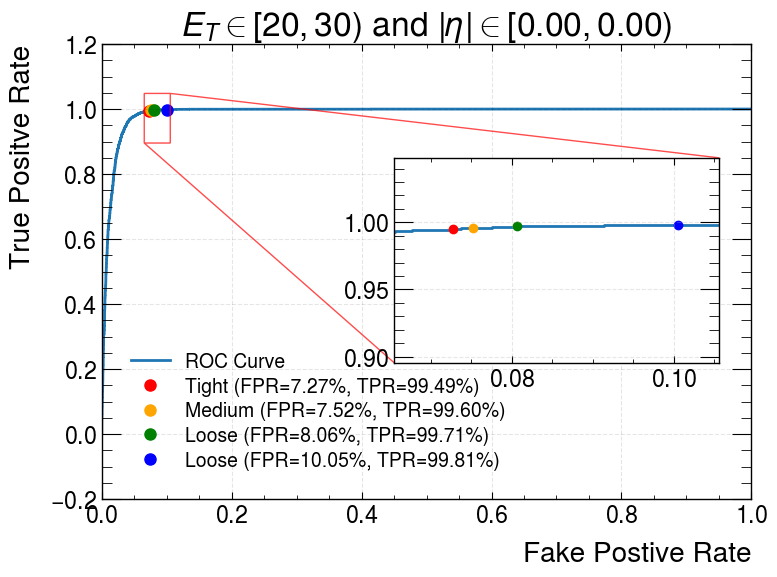

 [Thu, 06 Aug 2026 15:03:32] INFO Substituting symbol \in from Computer Modern


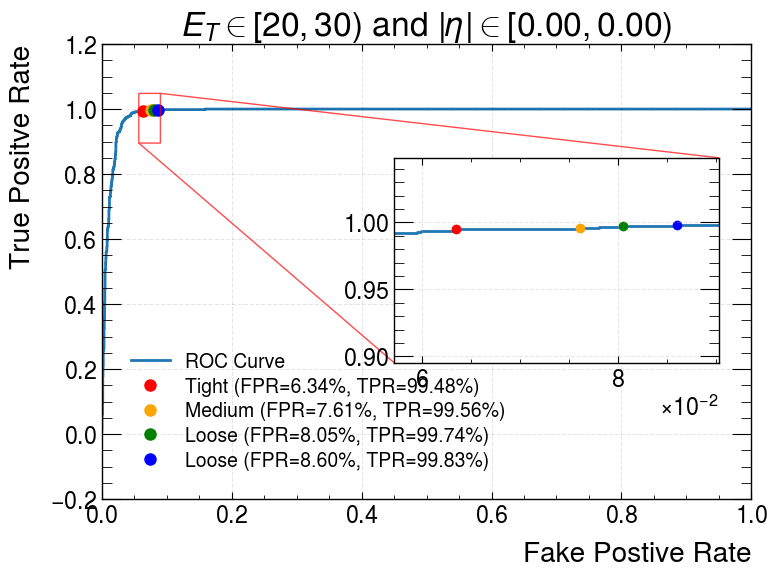

 [Thu, 06 Aug 2026 15:03:32] INFO Substituting symbol \in from Computer Modern


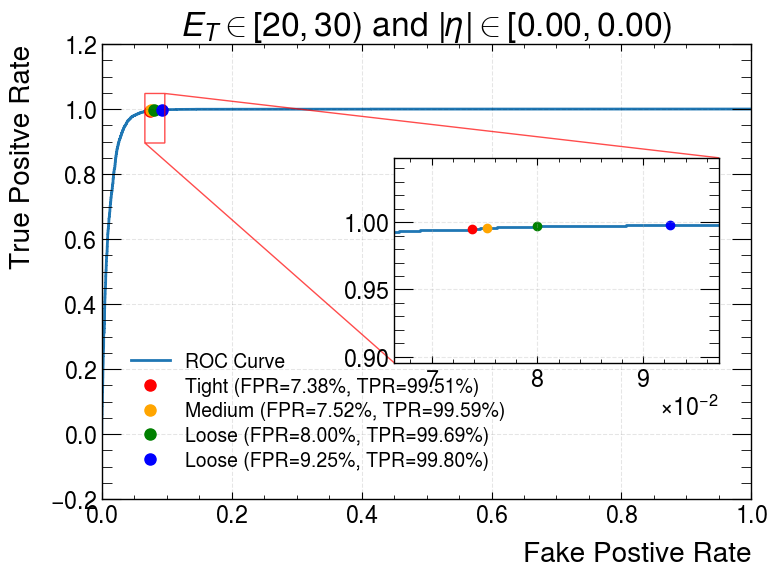

 [Thu, 06 Aug 2026 15:03:33] INFO Substituting symbol \in from Computer Modern


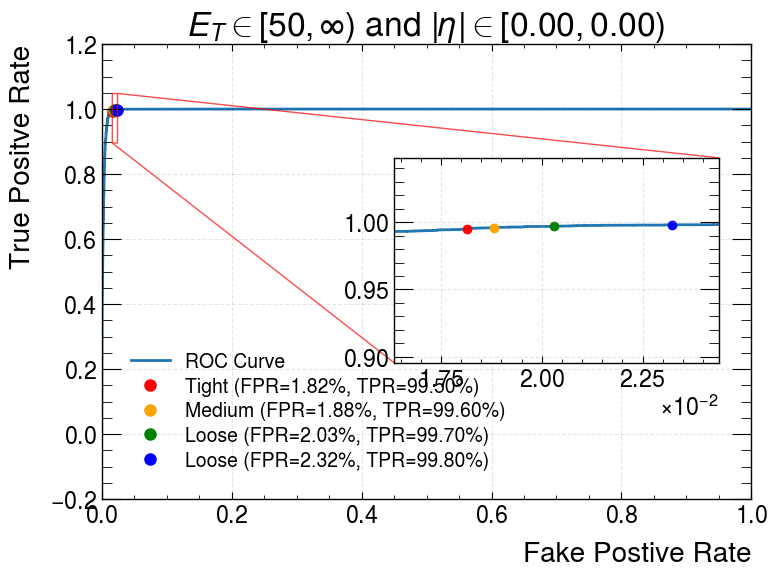

 [Thu, 06 Aug 2026 15:03:33] INFO Substituting symbol \in from Computer Modern


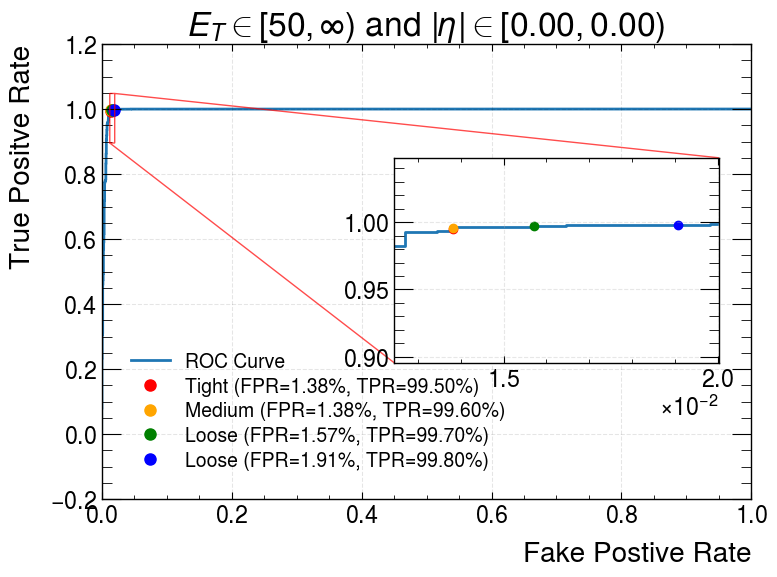

 [Thu, 06 Aug 2026 15:03:33] INFO Substituting symbol \in from Computer Modern


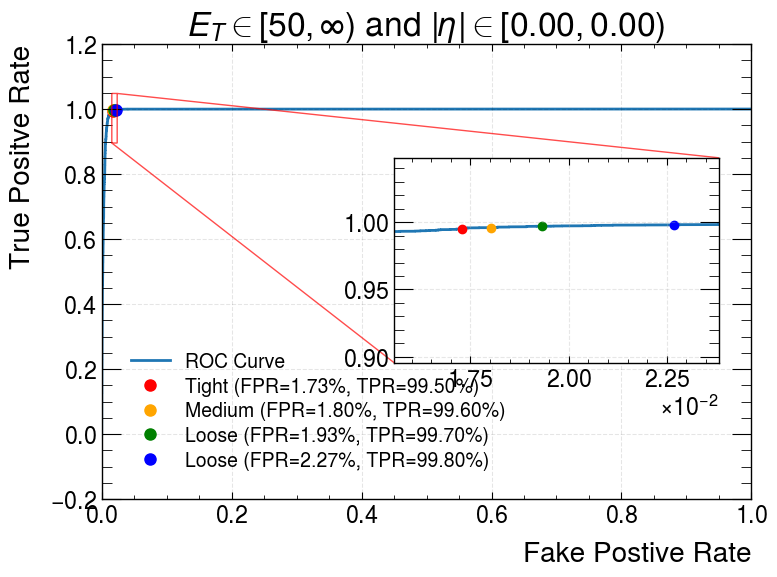

 [Thu, 06 Aug 2026 15:03:33] INFO Substituting symbol \in from Computer Modern


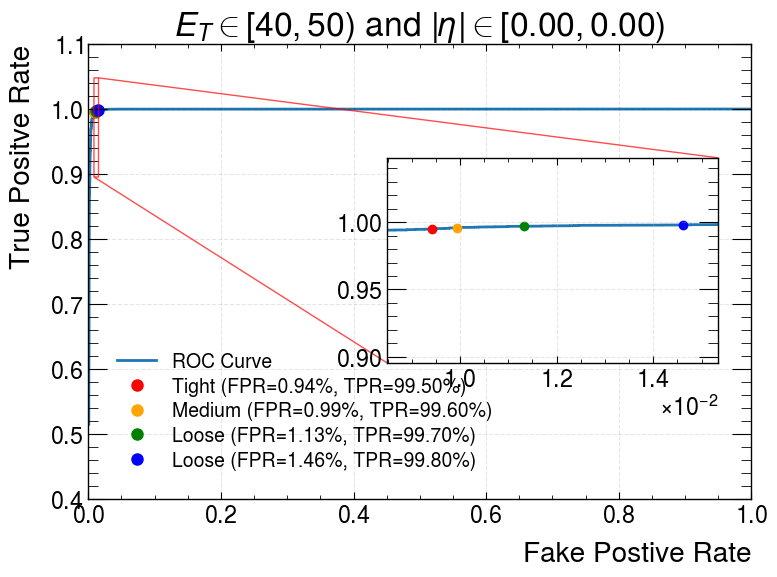

 [Thu, 06 Aug 2026 15:03:34] INFO Substituting symbol \in from Computer Modern


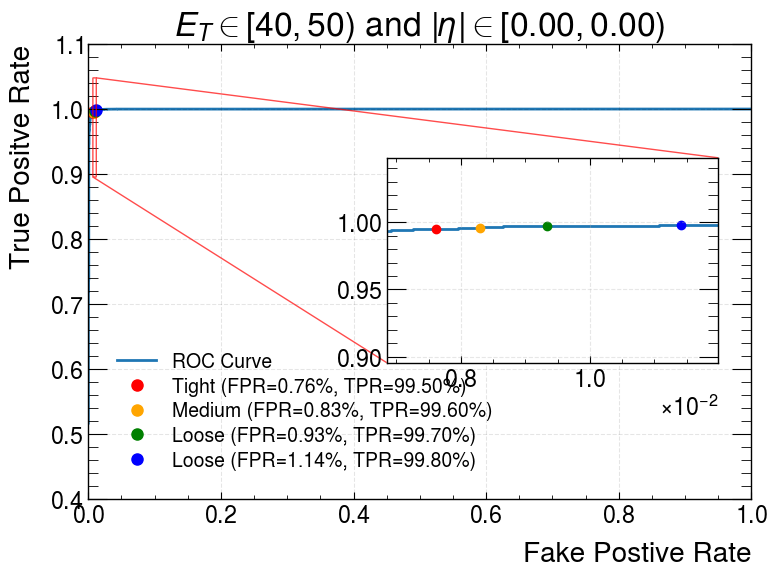

 [Thu, 06 Aug 2026 15:03:34] INFO Substituting symbol \in from Computer Modern


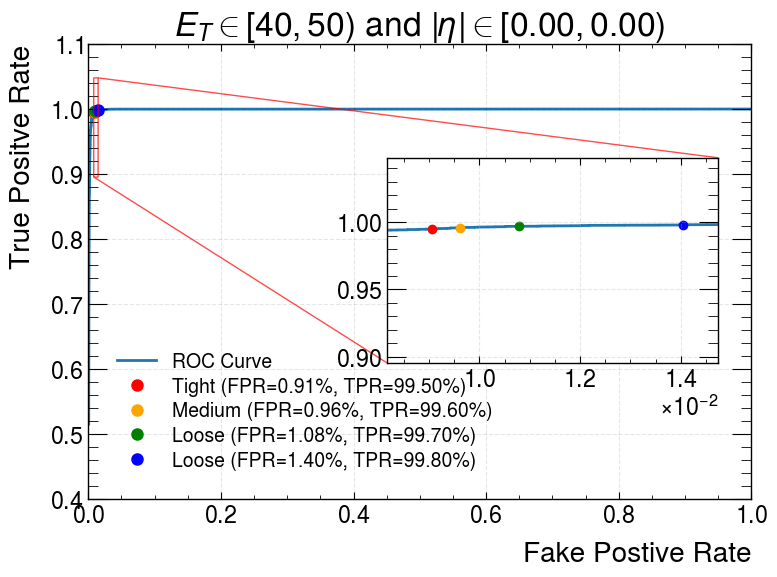

 [Thu, 06 Aug 2026 15:03:34] INFO Substituting symbol \in from Computer Modern


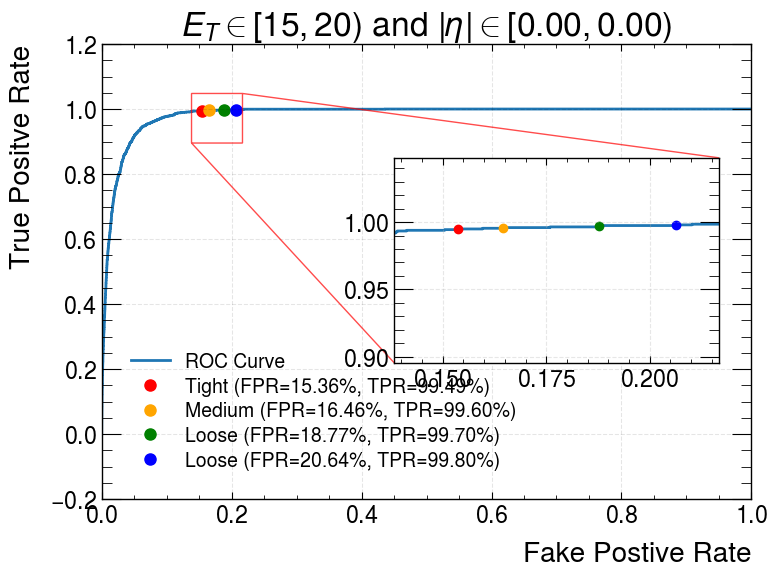

 [Thu, 06 Aug 2026 15:03:34] INFO Substituting symbol \in from Computer Modern


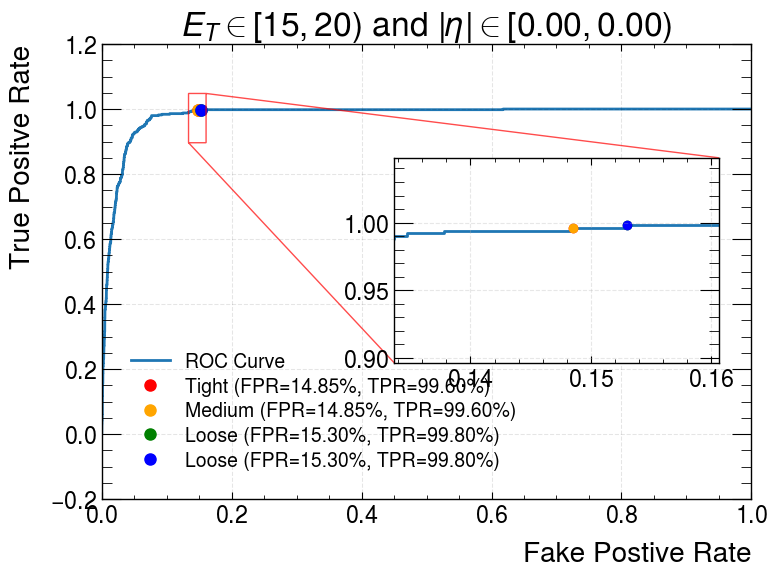

 [Thu, 06 Aug 2026 15:03:34] INFO Substituting symbol \in from Computer Modern


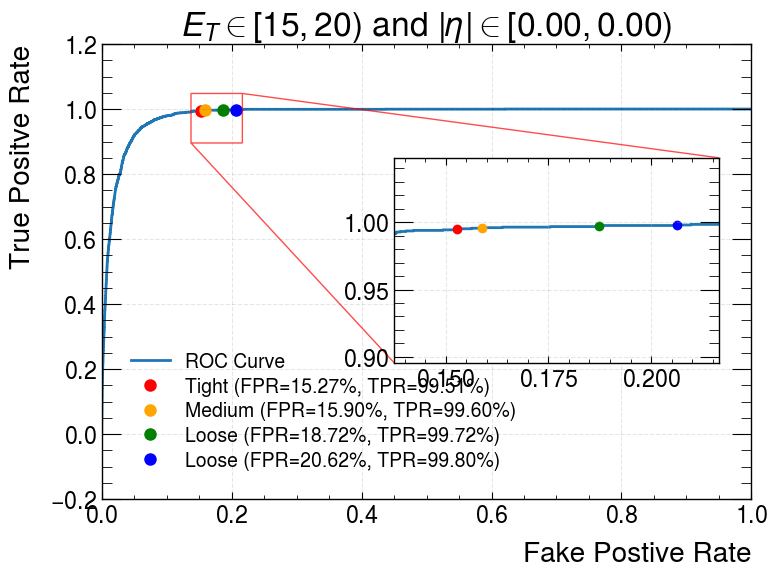

 [Thu, 06 Aug 2026 15:03:35] INFO Substituting symbol \in from Computer Modern


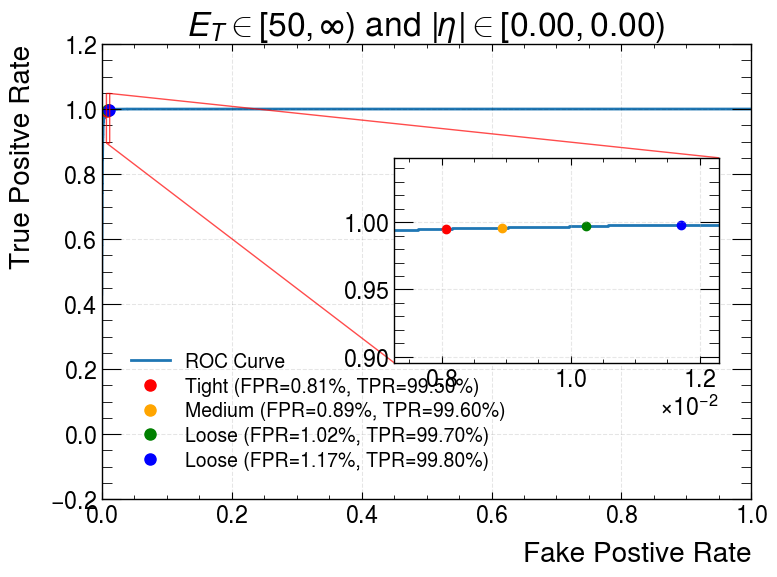

 [Thu, 06 Aug 2026 15:03:35] INFO Substituting symbol \in from Computer Modern


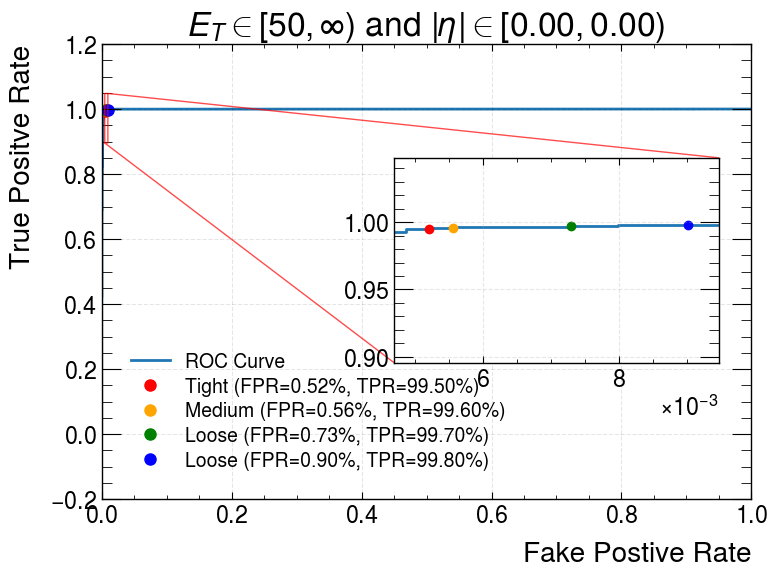

 [Thu, 06 Aug 2026 15:03:35] INFO Substituting symbol \in from Computer Modern


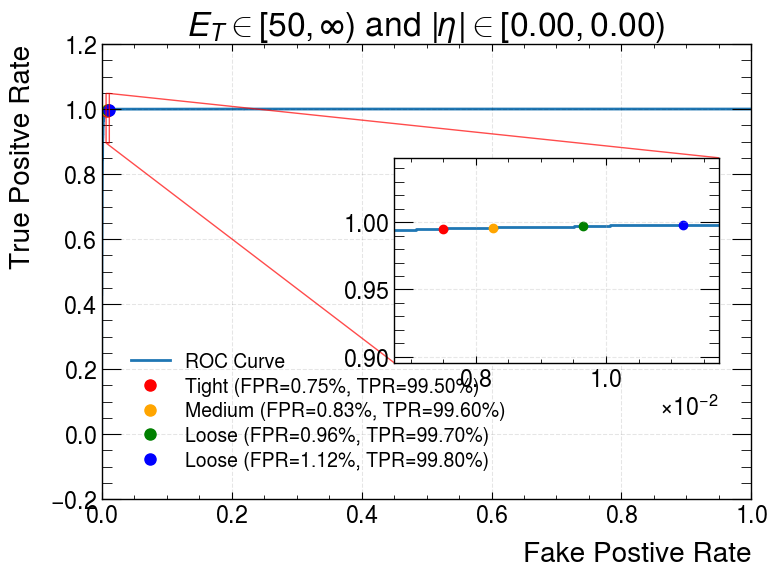

 [Thu, 06 Aug 2026 15:03:35] INFO Substituting symbol \in from Computer Modern


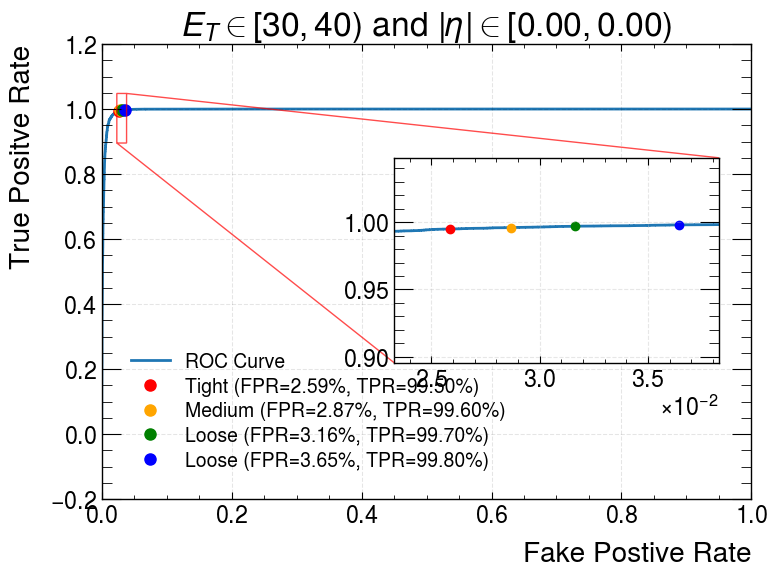

 [Thu, 06 Aug 2026 15:03:36] INFO Substituting symbol \in from Computer Modern


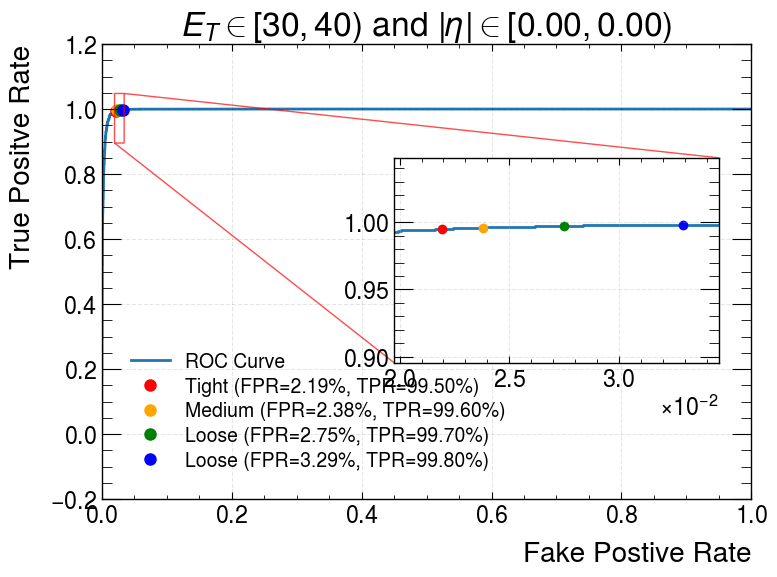

 [Thu, 06 Aug 2026 15:03:36] INFO Substituting symbol \in from Computer Modern


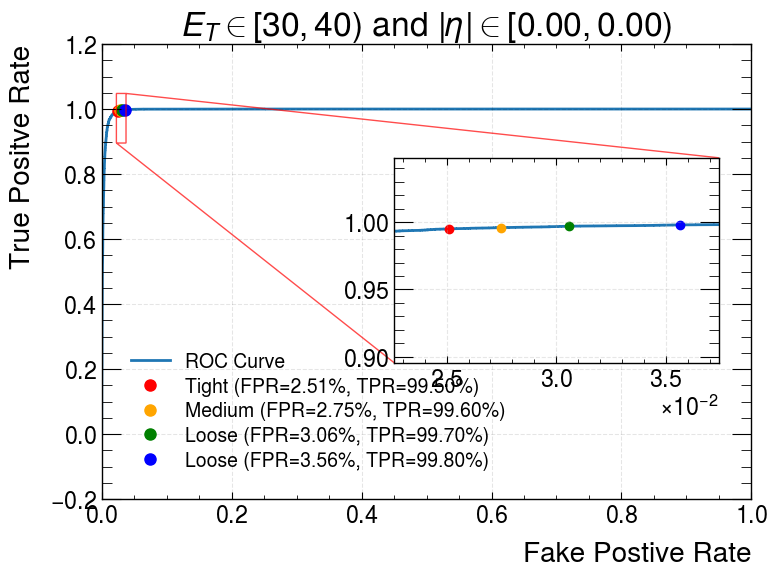

 [Thu, 06 Aug 2026 15:03:36] INFO Substituting symbol \in from Computer Modern


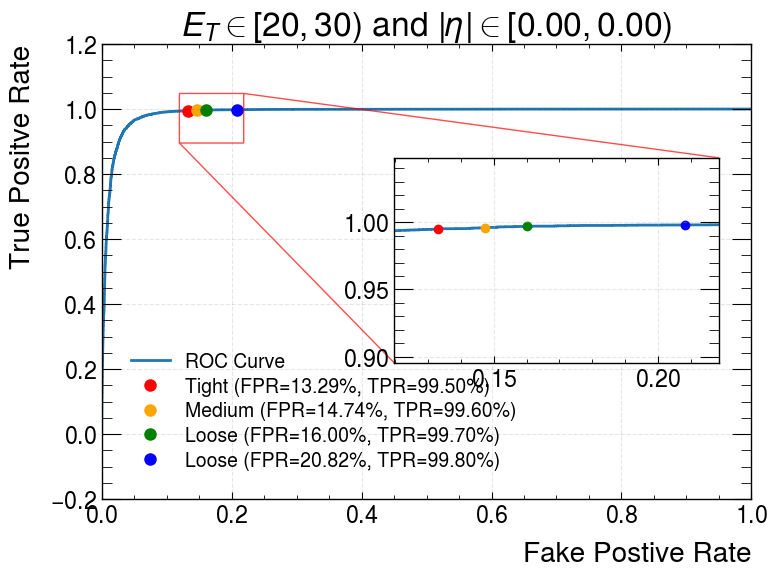

 [Thu, 06 Aug 2026 15:03:36] INFO Substituting symbol \in from Computer Modern


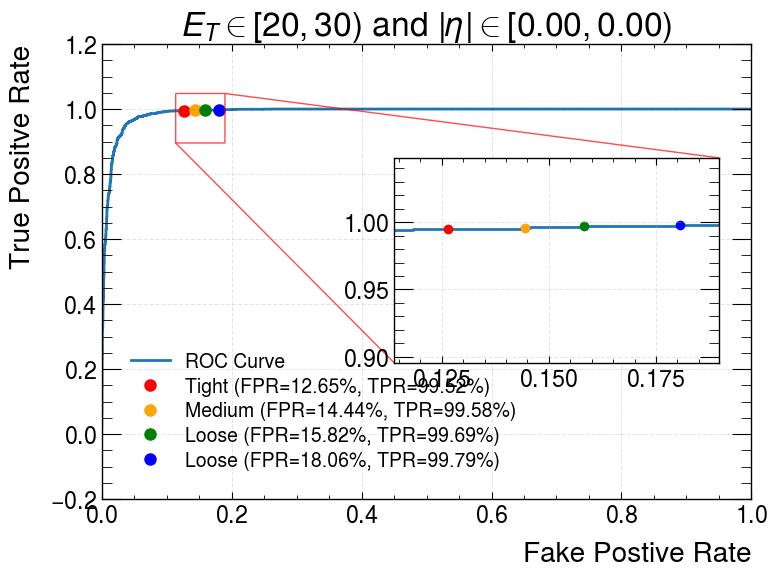

 [Thu, 06 Aug 2026 15:03:37] INFO Substituting symbol \in from Computer Modern


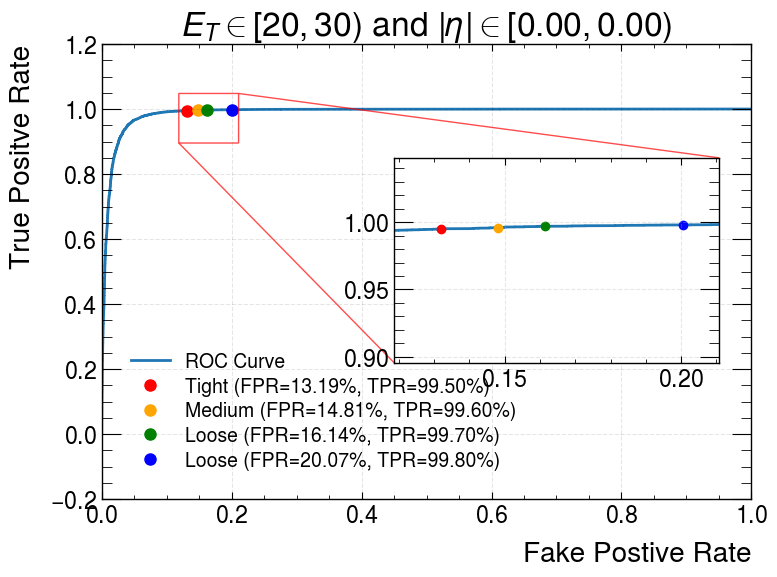

 [Thu, 06 Aug 2026 15:03:37] INFO Substituting symbol \in from Computer Modern


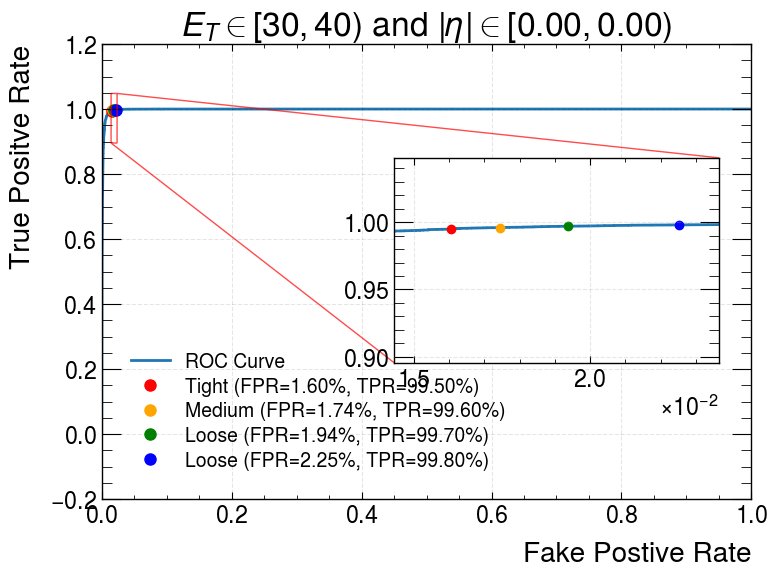

 [Thu, 06 Aug 2026 15:03:40] INFO Substituting symbol \in from Computer Modern


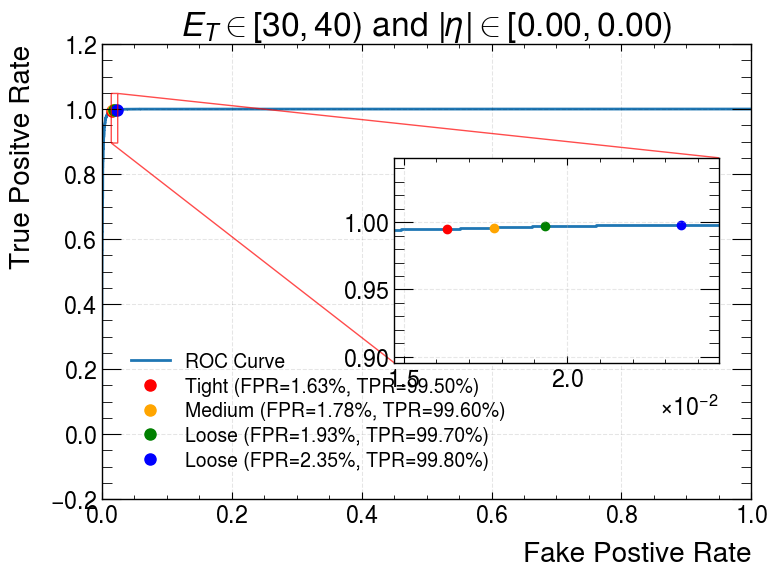

 [Thu, 06 Aug 2026 15:03:40] INFO Substituting symbol \in from Computer Modern


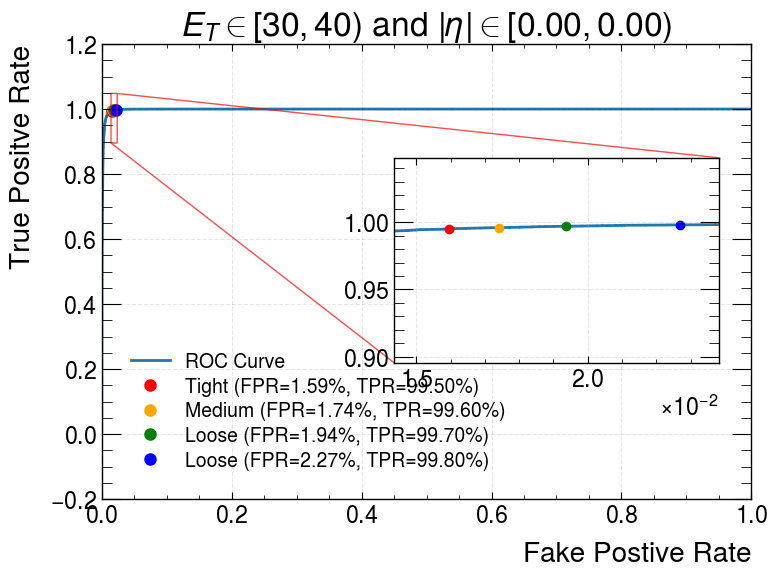

 [Thu, 06 Aug 2026 15:03:41] INFO Substituting symbol \in from Computer Modern


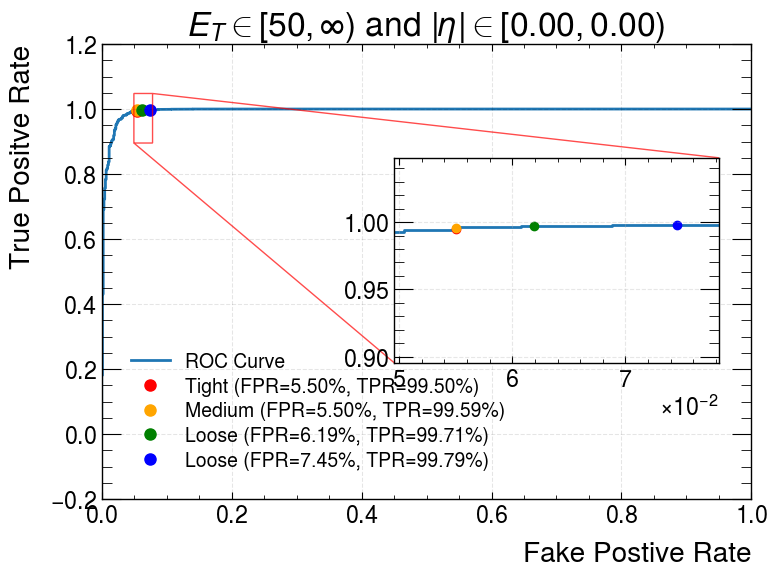

 [Thu, 06 Aug 2026 15:03:41] INFO Substituting symbol \in from Computer Modern


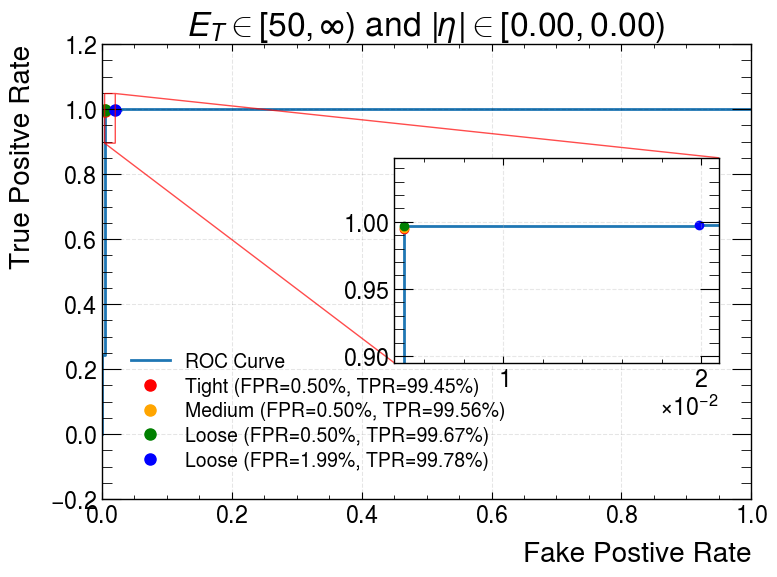

 [Thu, 06 Aug 2026 15:03:41] INFO Substituting symbol \in from Computer Modern


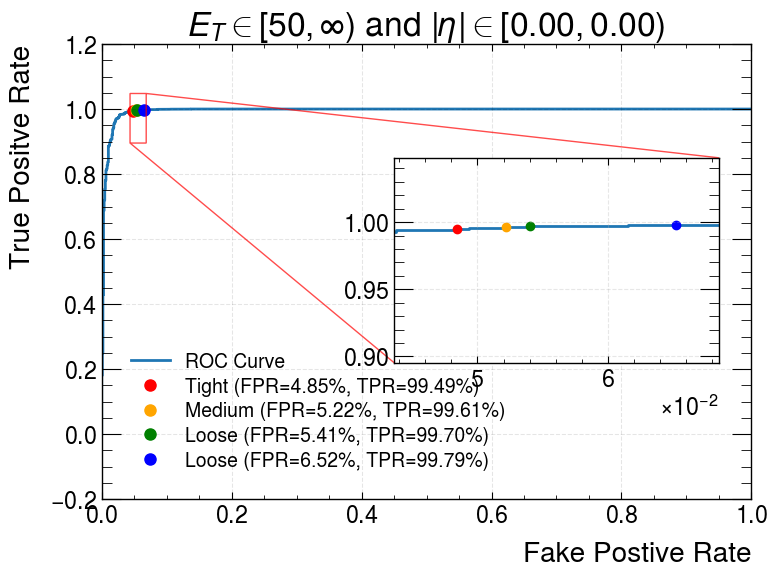

 [Thu, 06 Aug 2026 15:03:41] INFO Substituting symbol \in from Computer Modern


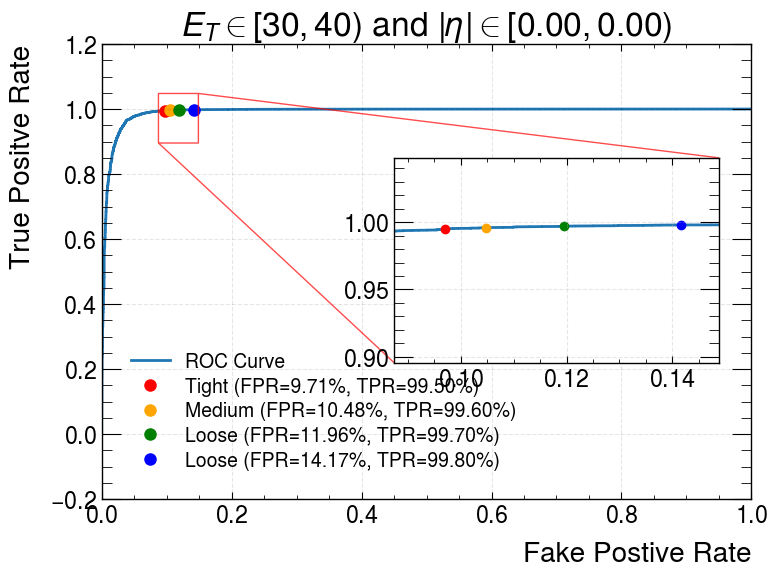

 [Thu, 06 Aug 2026 15:03:41] INFO Substituting symbol \in from Computer Modern


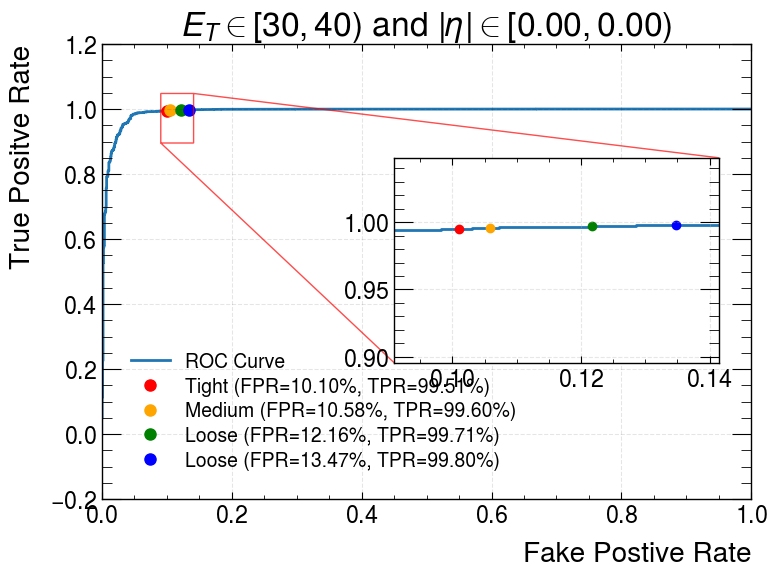

 [Thu, 06 Aug 2026 15:03:42] INFO Substituting symbol \in from Computer Modern


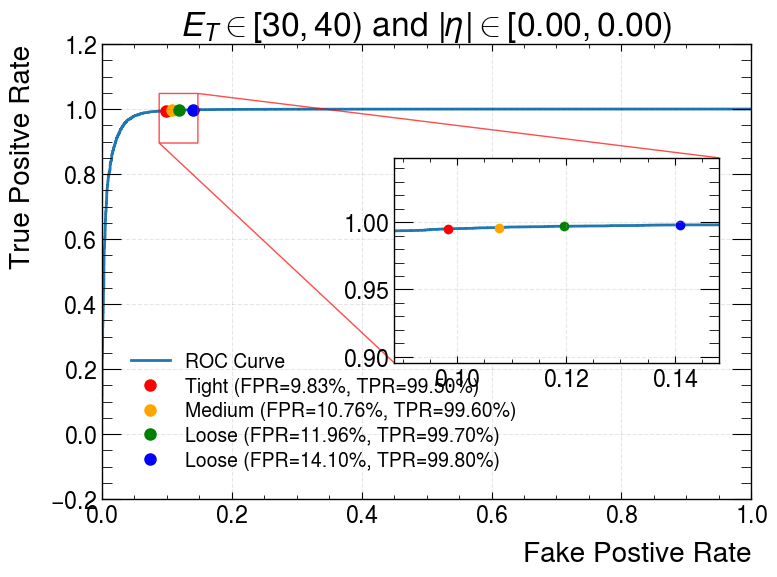

 [Thu, 06 Aug 2026 15:03:42] INFO Substituting symbol \in from Computer Modern


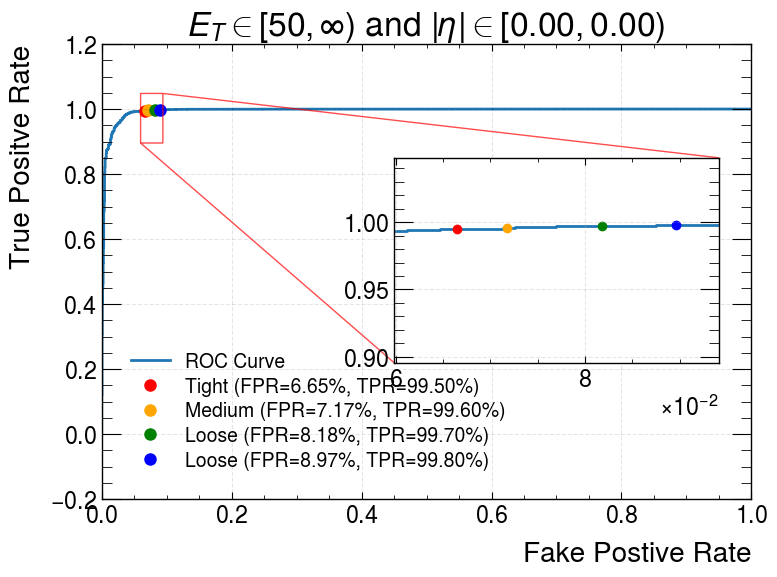

 [Thu, 06 Aug 2026 15:03:42] INFO Substituting symbol \in from Computer Modern


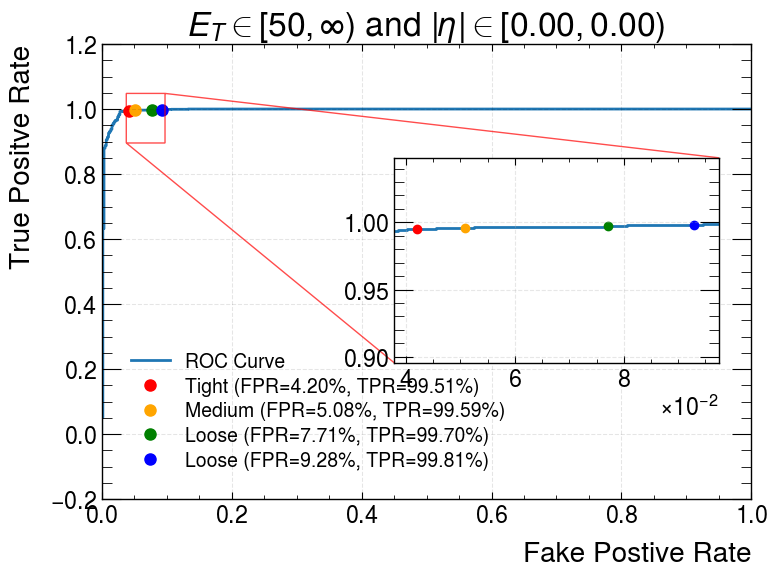

 [Thu, 06 Aug 2026 15:03:42] INFO Substituting symbol \in from Computer Modern


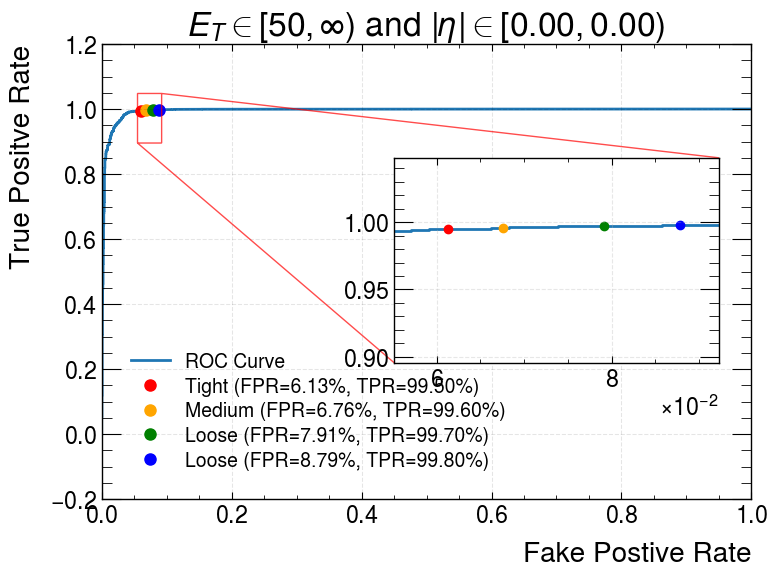

 [Thu, 06 Aug 2026 15:03:43] INFO Substituting symbol \in from Computer Modern


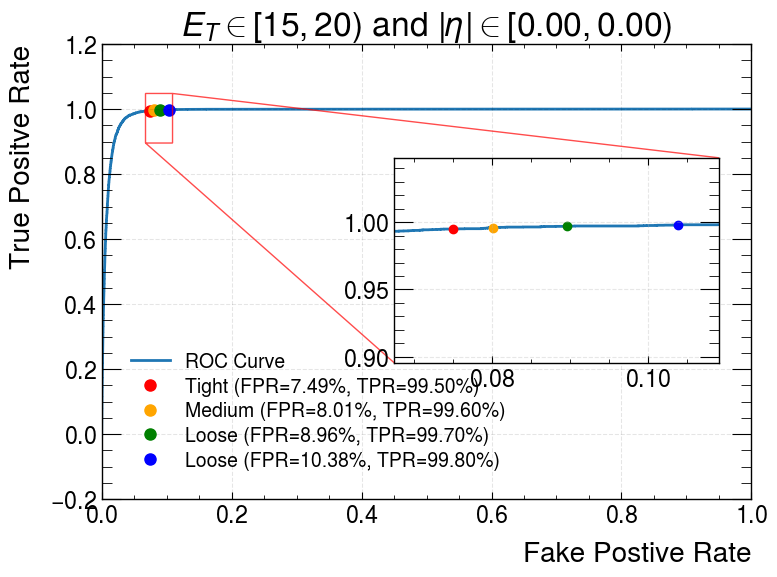

 [Thu, 06 Aug 2026 15:03:43] INFO Substituting symbol \in from Computer Modern


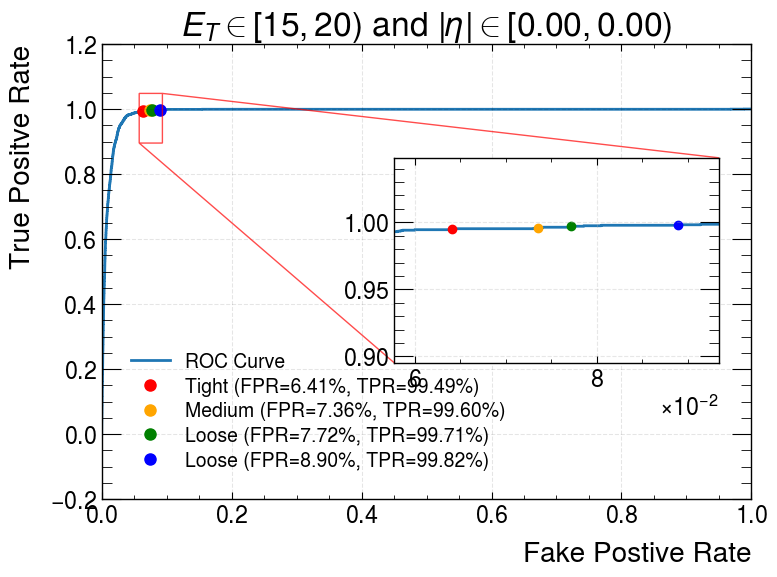

 [Thu, 06 Aug 2026 15:03:43] INFO Substituting symbol \in from Computer Modern


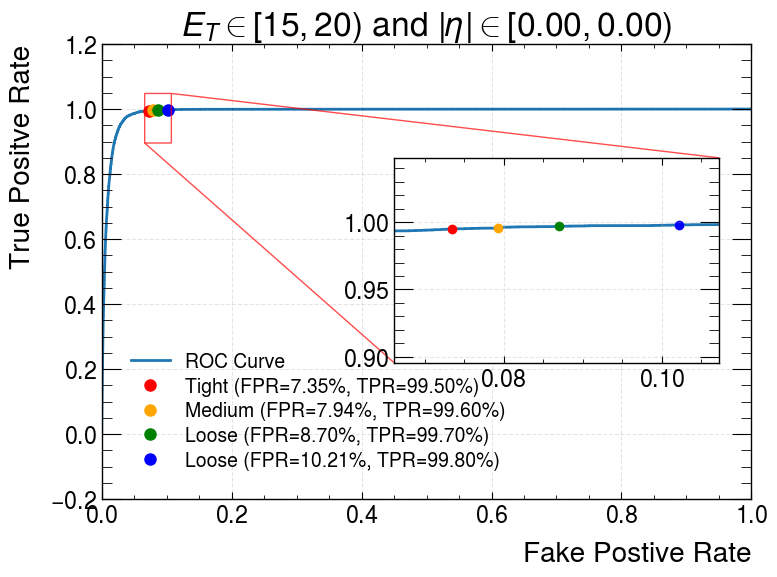

 [Thu, 06 Aug 2026 15:03:43] INFO Substituting symbol \in from Computer Modern


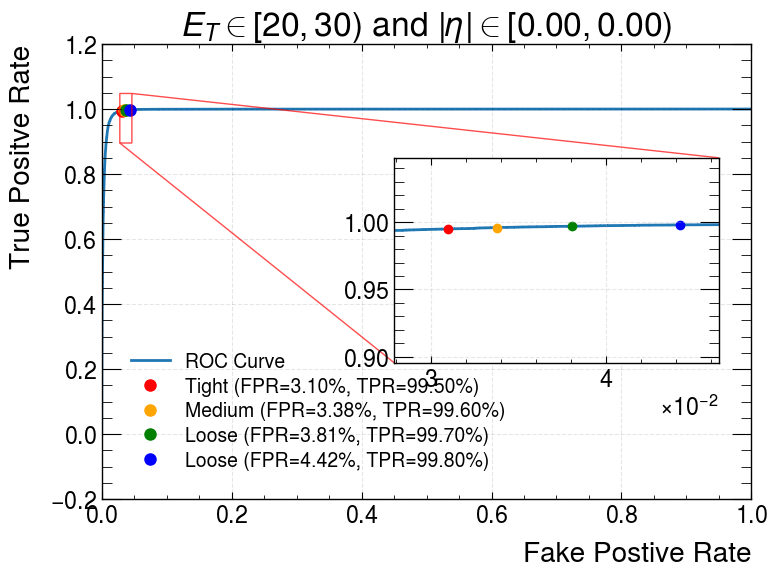

 [Thu, 06 Aug 2026 15:03:44] INFO Substituting symbol \in from Computer Modern


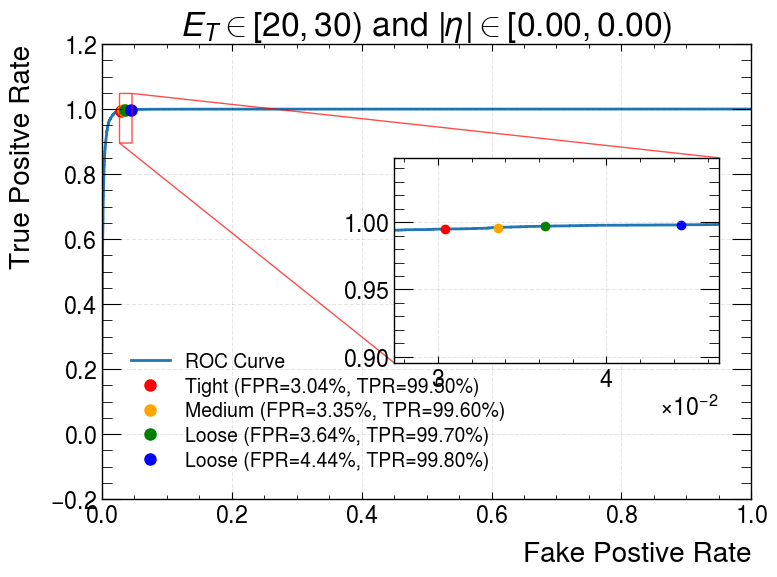

 [Thu, 06 Aug 2026 15:03:44] INFO Substituting symbol \in from Computer Modern


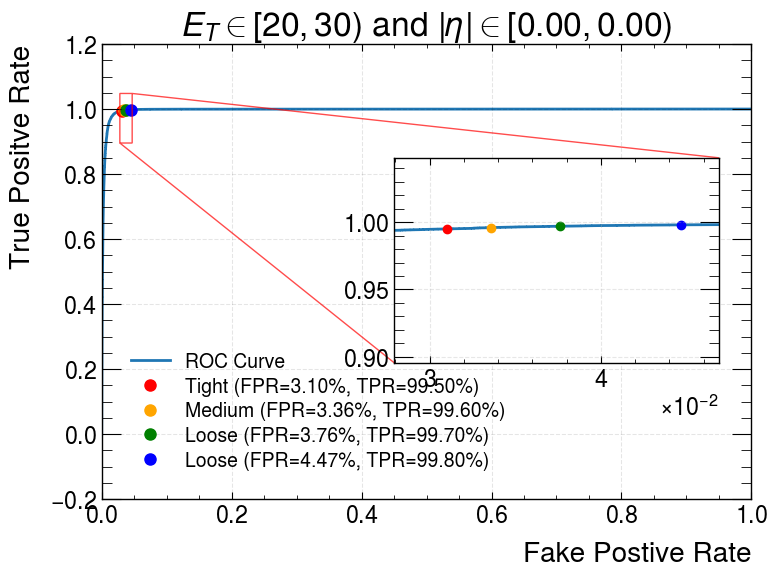

 [Thu, 06 Aug 2026 15:03:44] INFO Substituting symbol \in from Computer Modern


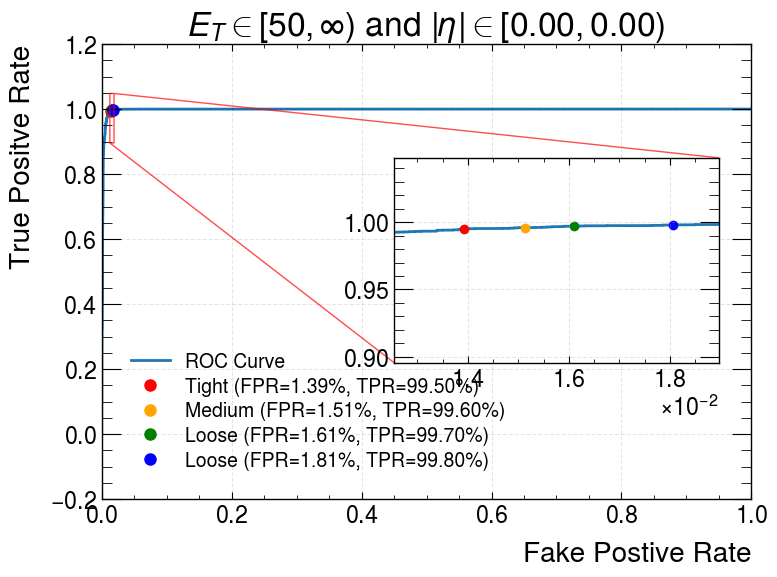

 [Thu, 06 Aug 2026 15:03:45] INFO Substituting symbol \in from Computer Modern


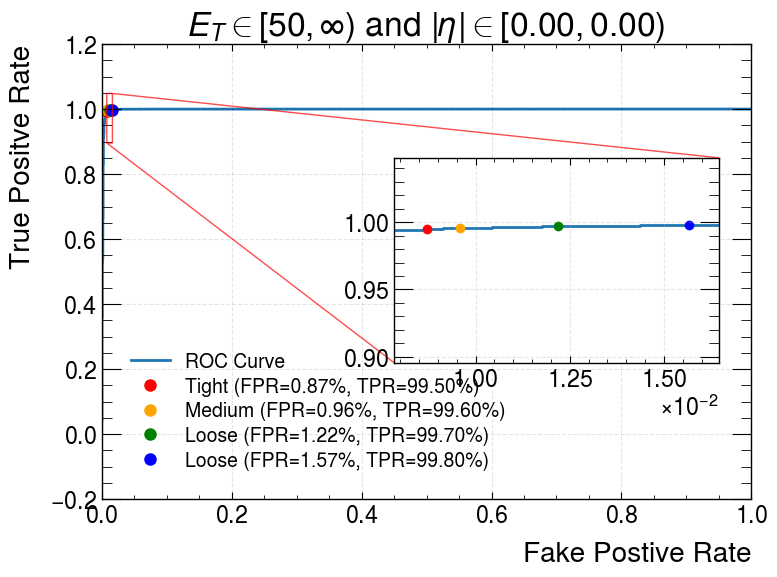

 [Thu, 06 Aug 2026 15:03:45] INFO Substituting symbol \in from Computer Modern


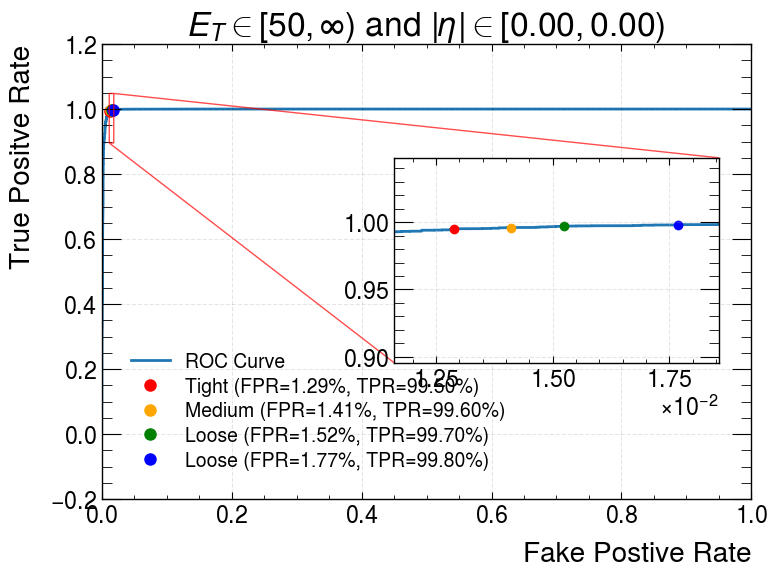

 [Thu, 06 Aug 2026 15:03:45] INFO Substituting symbol \in from Computer Modern


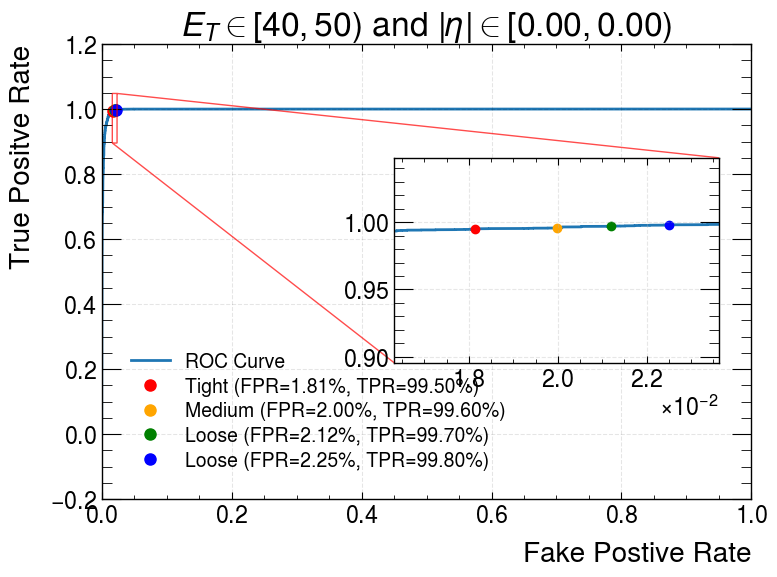

 [Thu, 06 Aug 2026 15:03:45] INFO Substituting symbol \in from Computer Modern


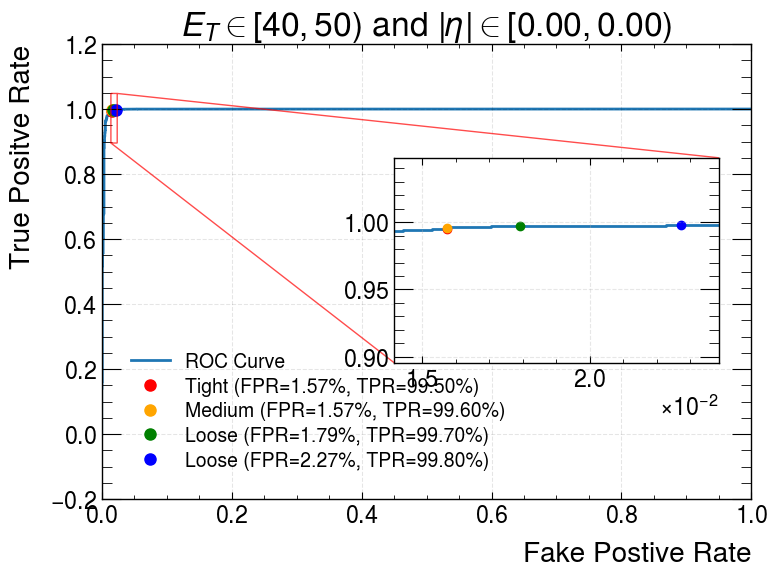

 [Thu, 06 Aug 2026 15:03:46] INFO Substituting symbol \in from Computer Modern


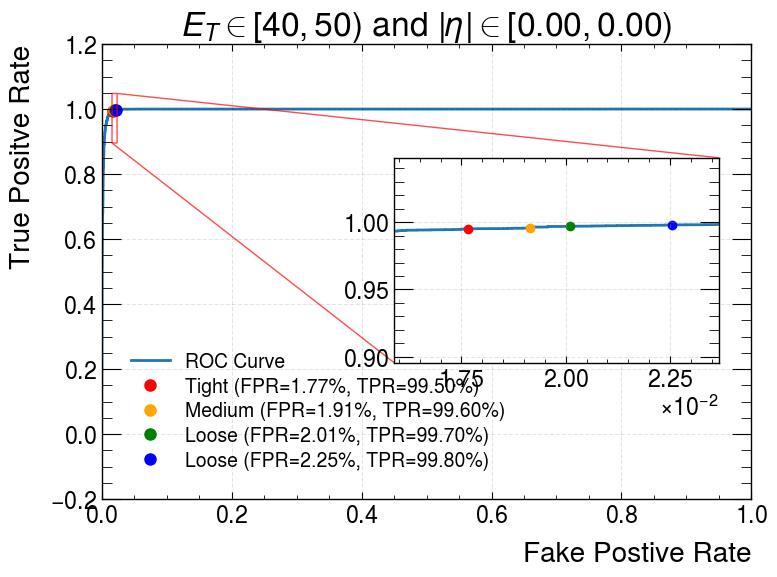

 [Thu, 06 Aug 2026 15:03:46] INFO Substituting symbol \in from Computer Modern


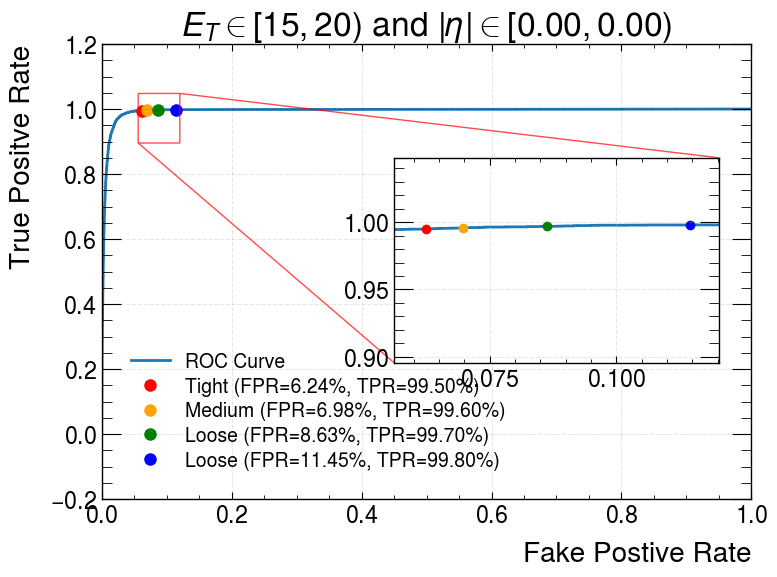

 [Thu, 06 Aug 2026 15:03:46] INFO Substituting symbol \in from Computer Modern


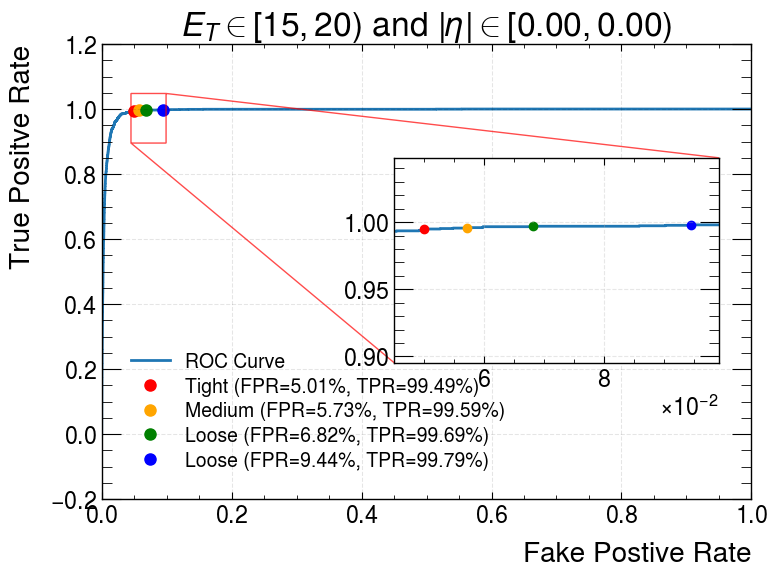

 [Thu, 06 Aug 2026 15:03:47] INFO Substituting symbol \in from Computer Modern


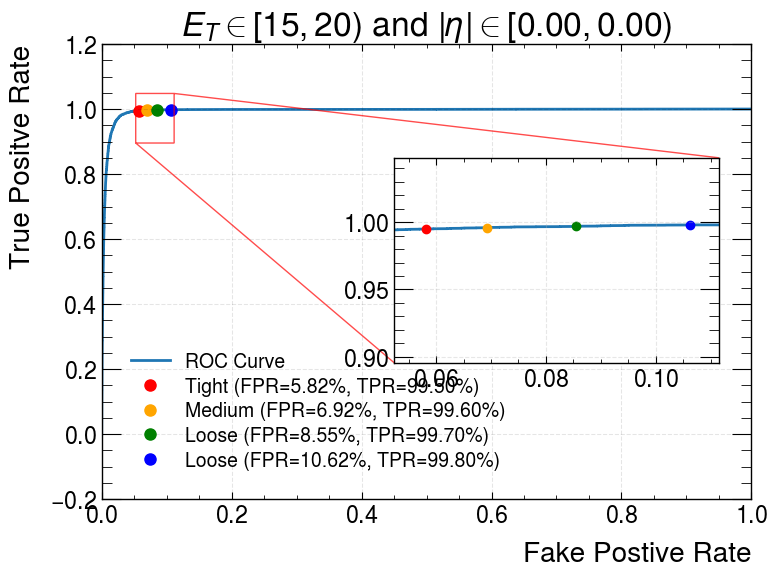

 [Thu, 06 Aug 2026 15:03:47] INFO Substituting symbol \in from Computer Modern


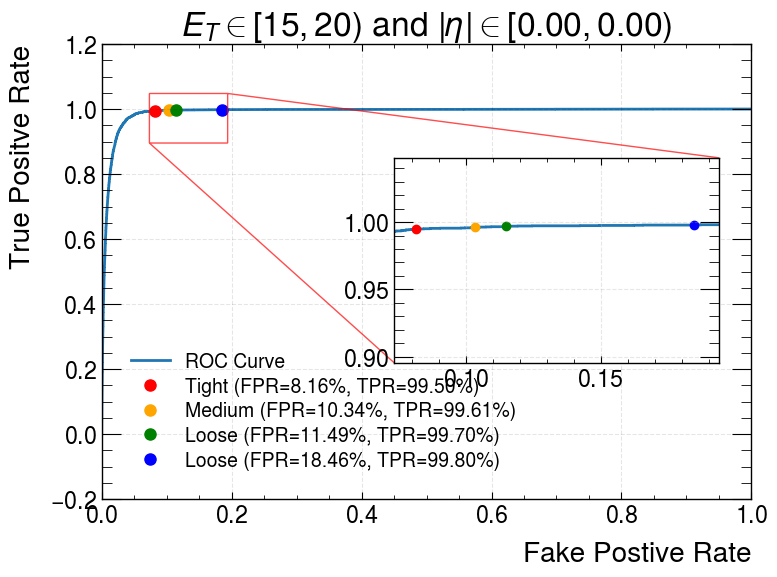

 [Thu, 06 Aug 2026 15:03:47] INFO Substituting symbol \in from Computer Modern


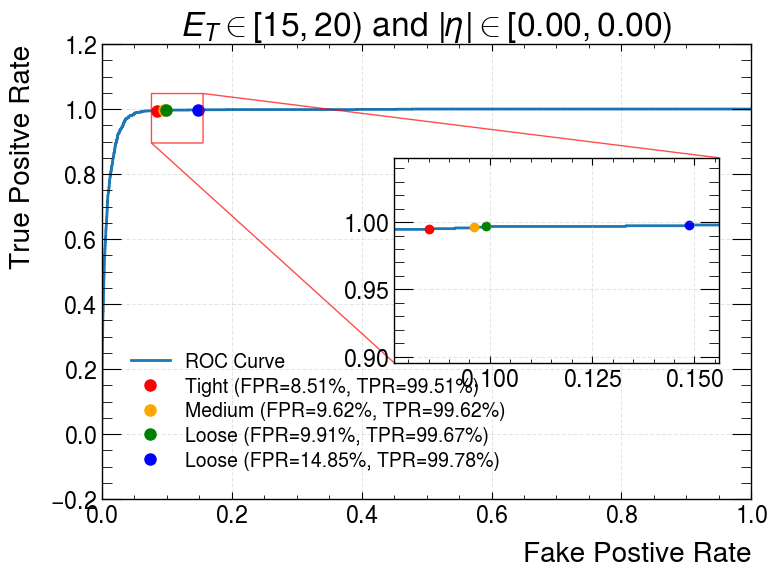

 [Thu, 06 Aug 2026 15:03:47] INFO Substituting symbol \in from Computer Modern


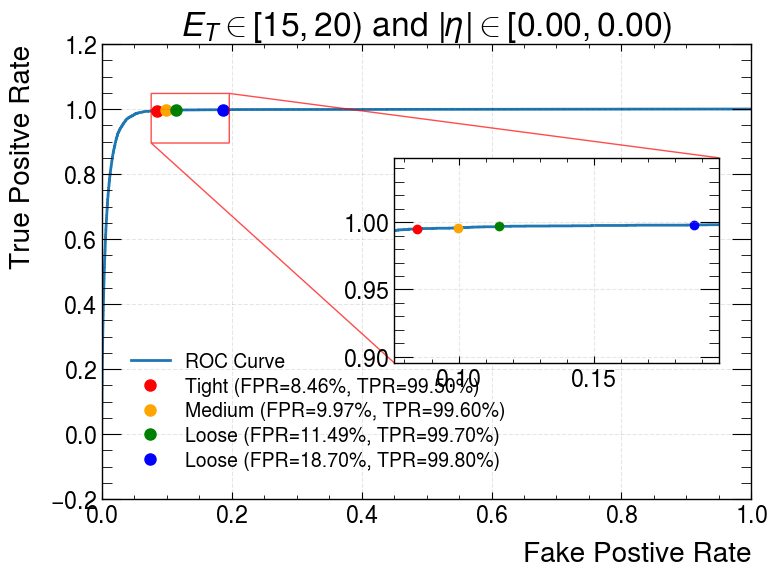

 [Thu, 06 Aug 2026 15:03:48] INFO Substituting symbol \in from Computer Modern


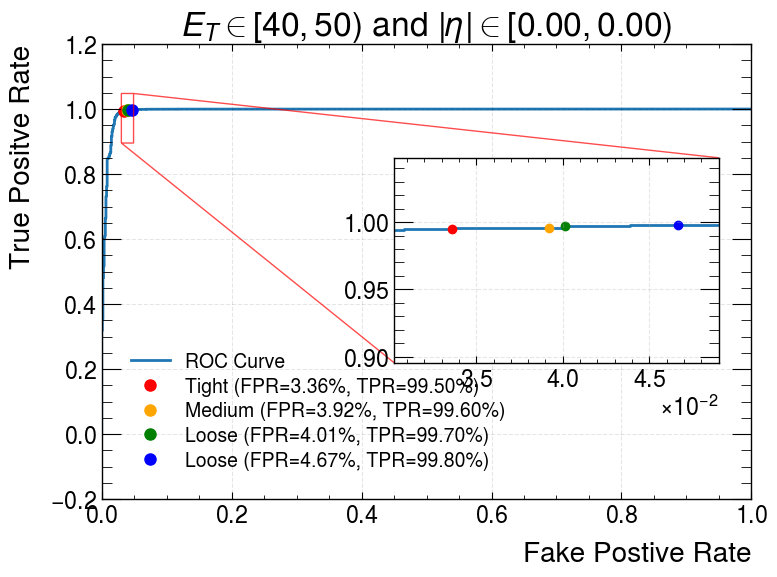

 [Thu, 06 Aug 2026 15:03:48] INFO Substituting symbol \in from Computer Modern


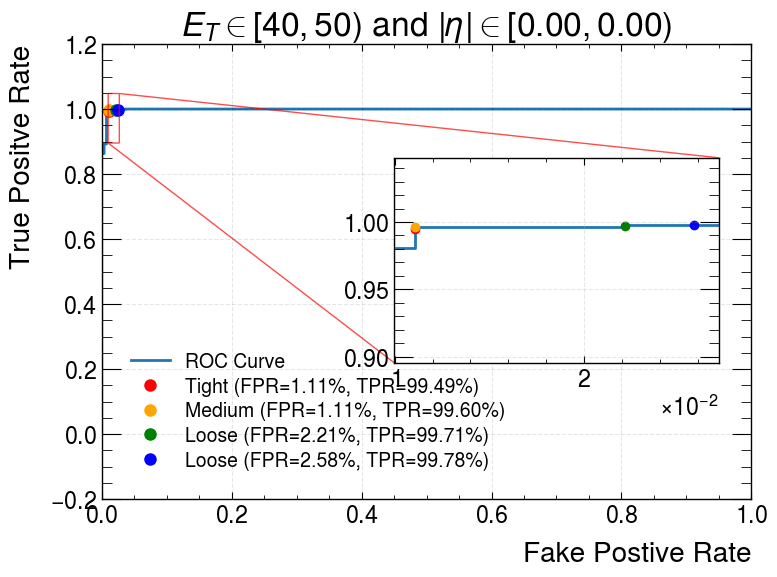

 [Thu, 06 Aug 2026 15:03:48] INFO Substituting symbol \in from Computer Modern


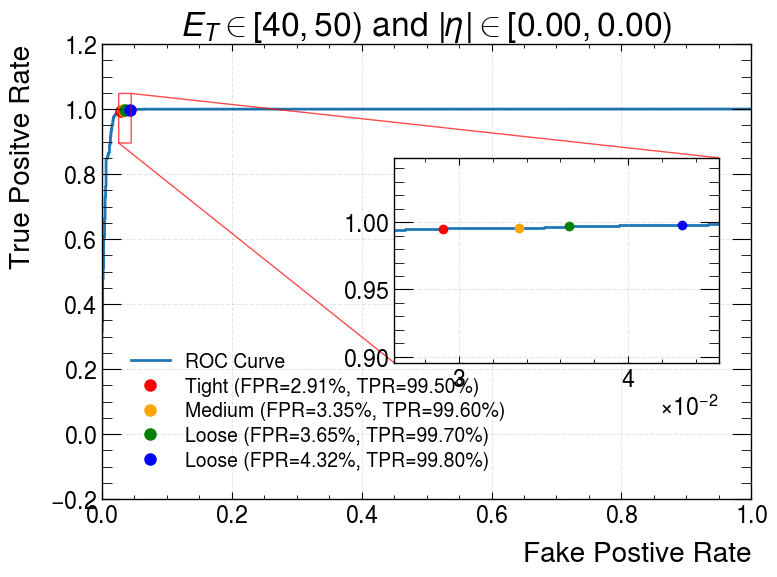

 [Thu, 06 Aug 2026 15:03:49] INFO Substituting symbol \in from Computer Modern


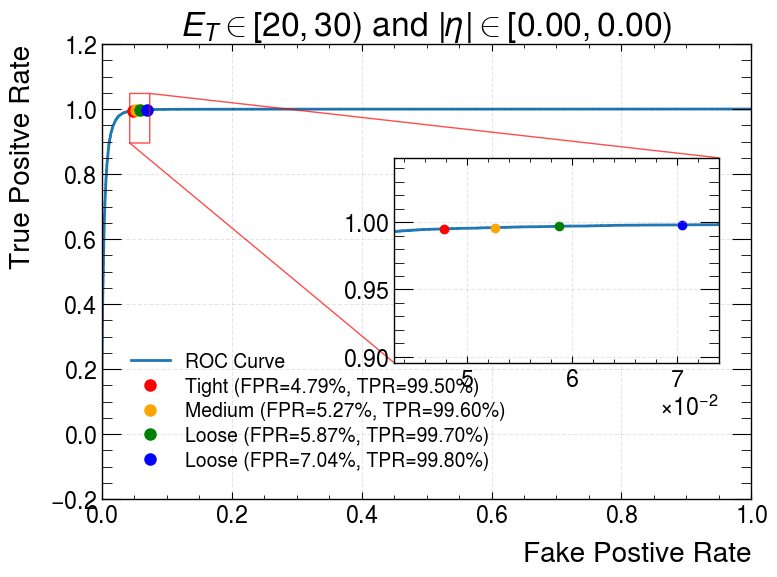

 [Thu, 06 Aug 2026 15:03:49] INFO Substituting symbol \in from Computer Modern


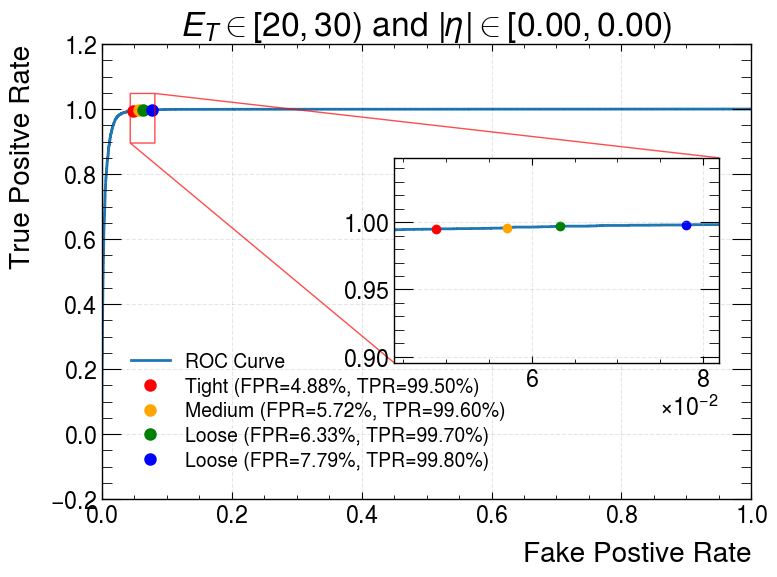

 [Thu, 06 Aug 2026 15:03:50] INFO Substituting symbol \in from Computer Modern


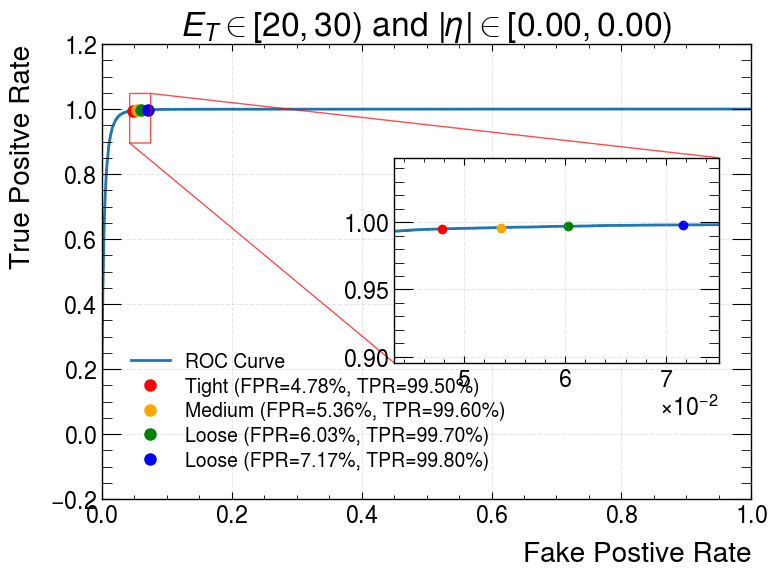

 [Thu, 06 Aug 2026 15:03:50] INFO Substituting symbol \in from Computer Modern


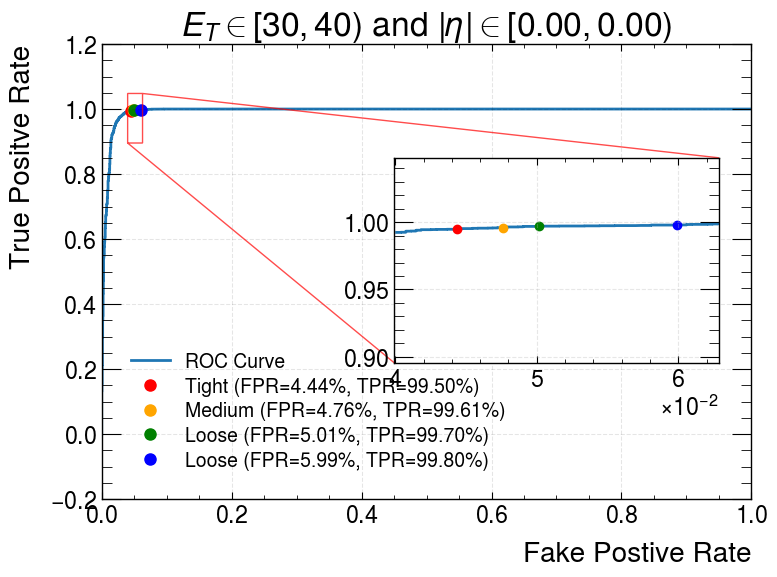

 [Thu, 06 Aug 2026 15:03:50] INFO Substituting symbol \in from Computer Modern


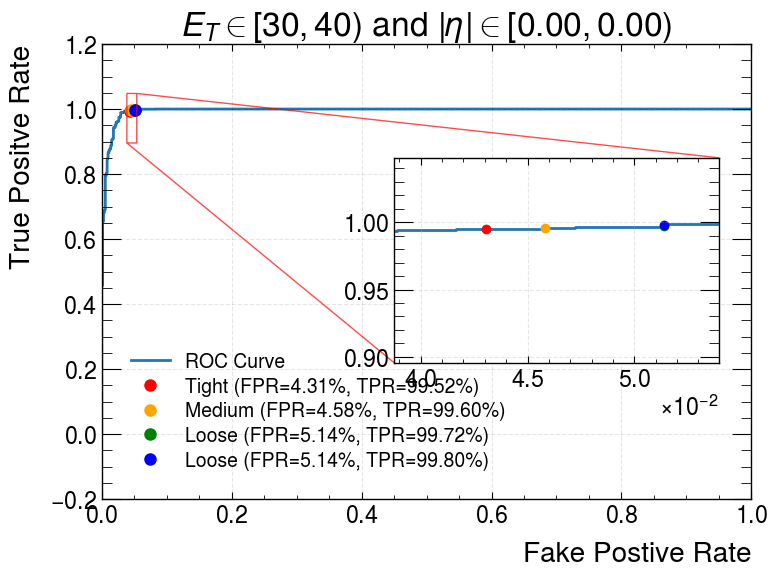

 [Thu, 06 Aug 2026 15:03:51] INFO Substituting symbol \in from Computer Modern


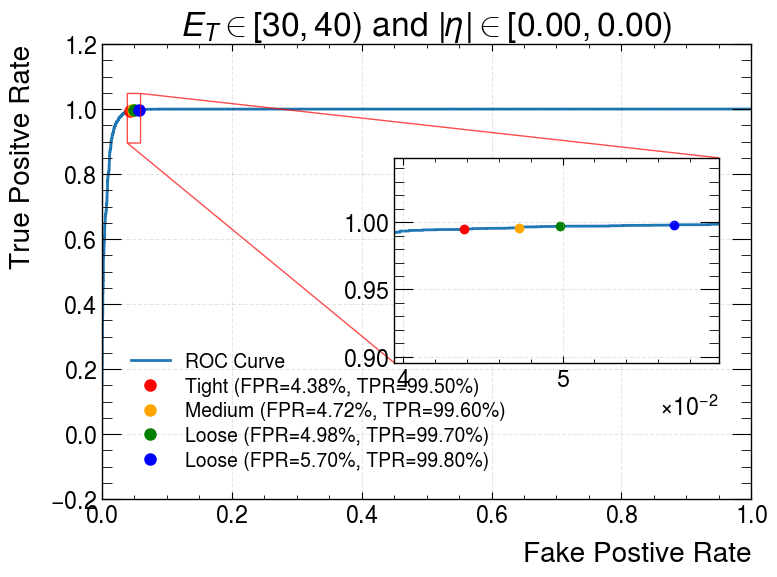

 [Thu, 06 Aug 2026 15:03:51] INFO Substituting symbol \in from Computer Modern


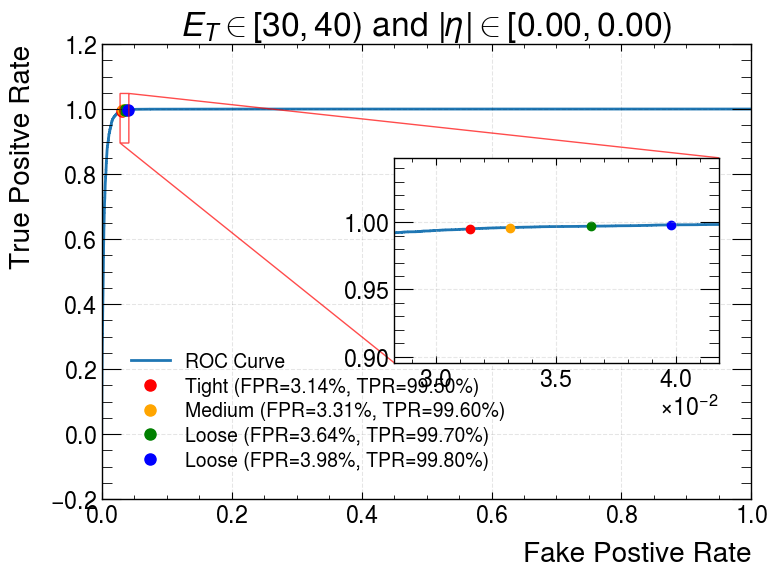

 [Thu, 06 Aug 2026 15:03:51] INFO Substituting symbol \in from Computer Modern


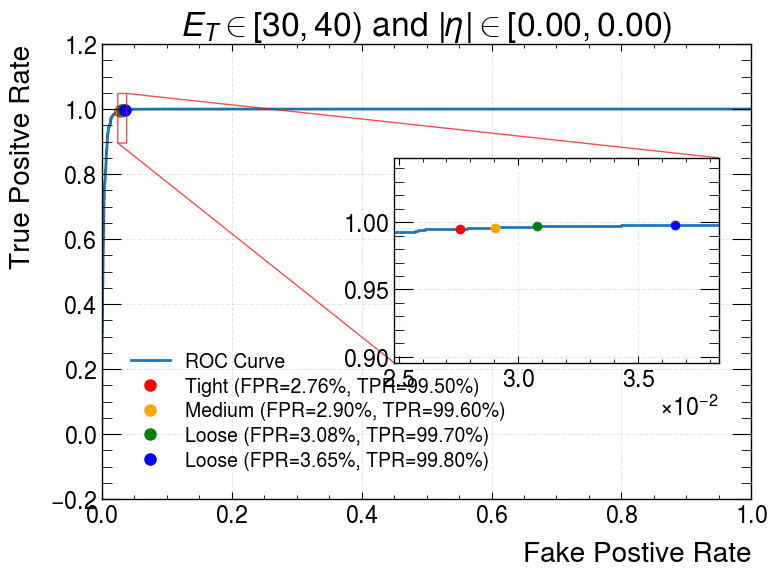

 [Thu, 06 Aug 2026 15:03:51] INFO Substituting symbol \in from Computer Modern


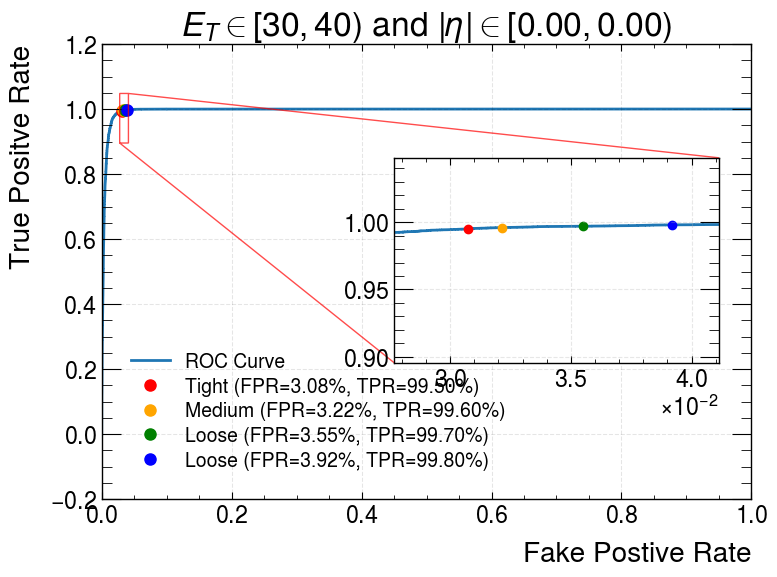

 [Thu, 06 Aug 2026 15:03:52] INFO Substituting symbol \in from Computer Modern


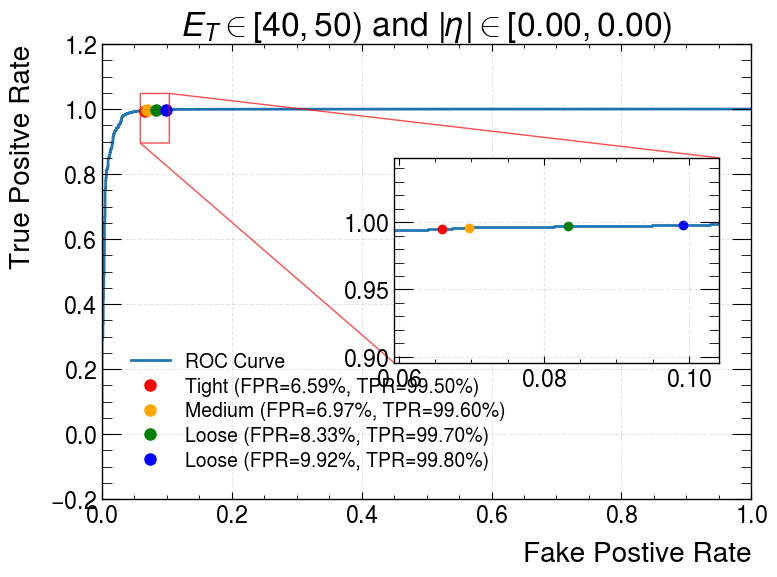

 [Thu, 06 Aug 2026 15:03:52] INFO Substituting symbol \in from Computer Modern


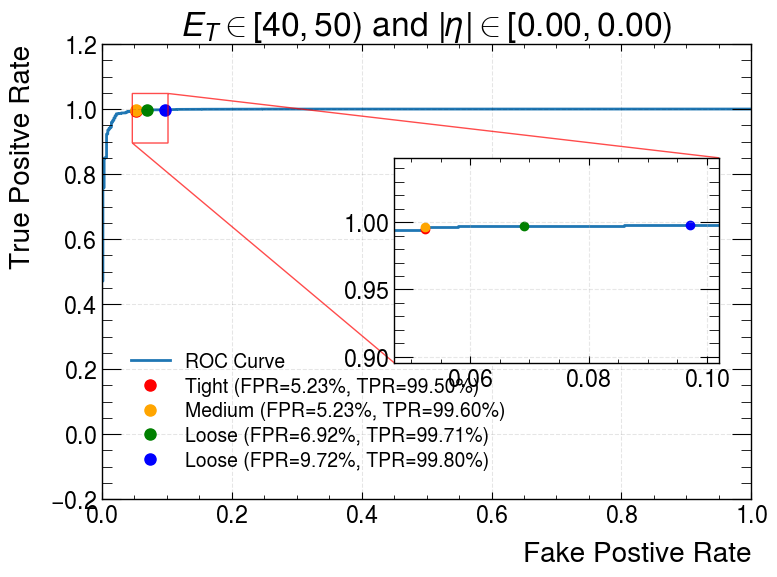

 [Thu, 06 Aug 2026 15:03:52] INFO Substituting symbol \in from Computer Modern


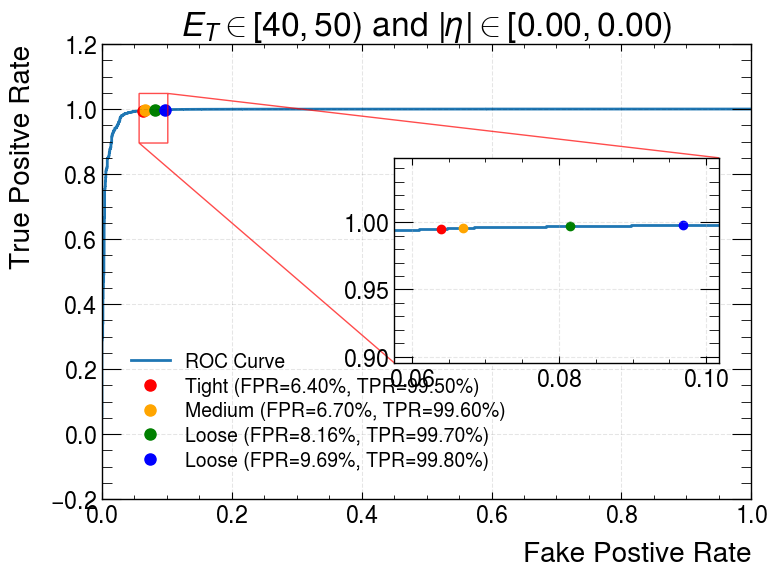

 [Thu, 06 Aug 2026 15:03:53] INFO Substituting symbol \in from Computer Modern


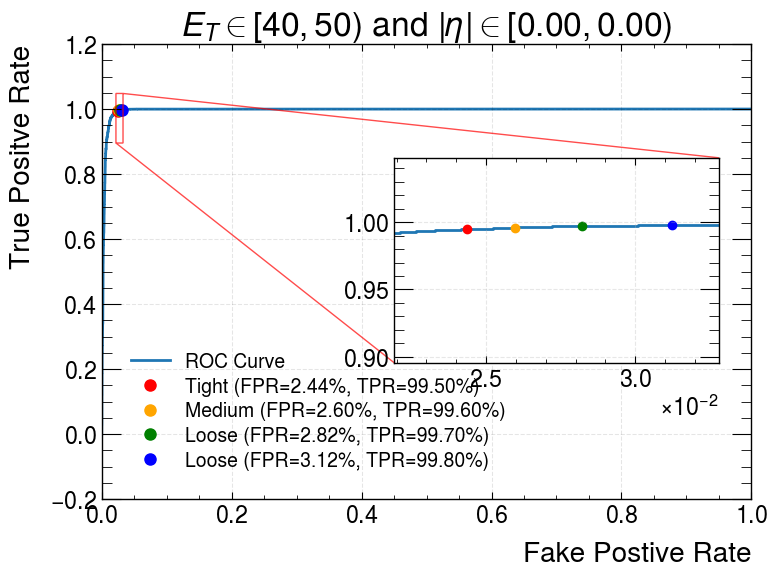

 [Thu, 06 Aug 2026 15:03:53] INFO Substituting symbol \in from Computer Modern


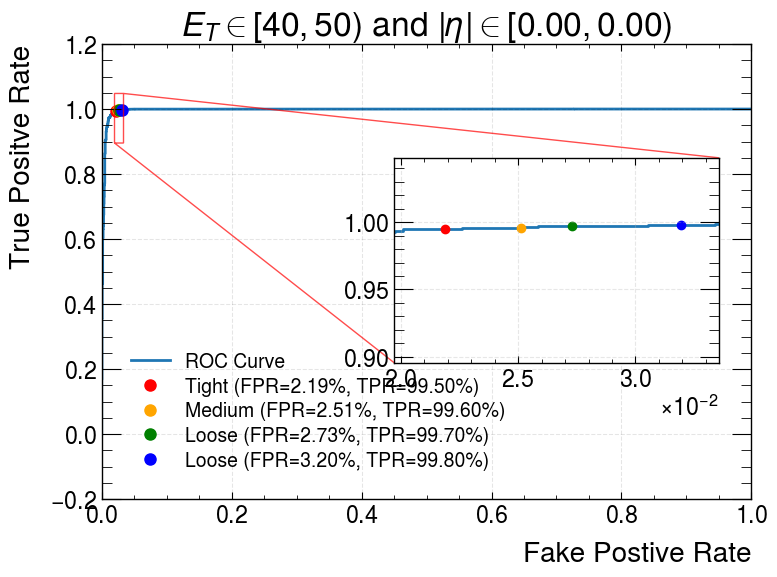

 [Thu, 06 Aug 2026 15:03:53] INFO Substituting symbol \in from Computer Modern


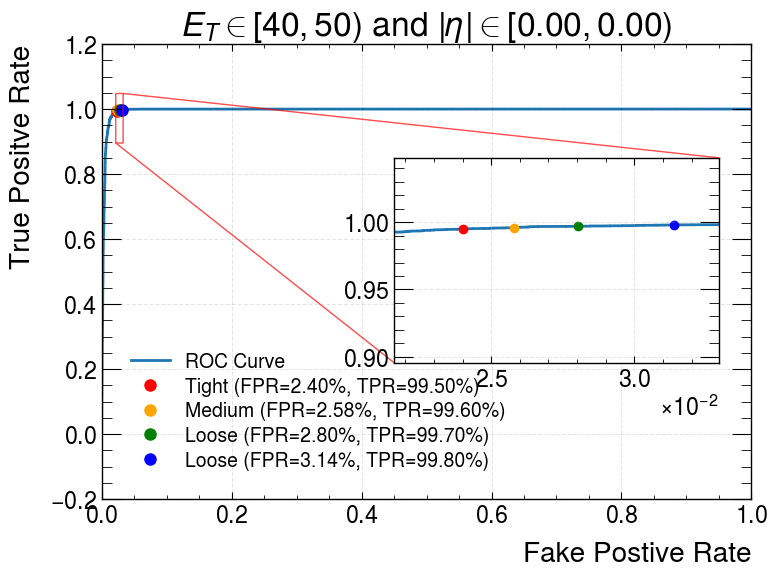

 [Thu, 06 Aug 2026 15:03:54] INFO Substituting symbol \in from Computer Modern


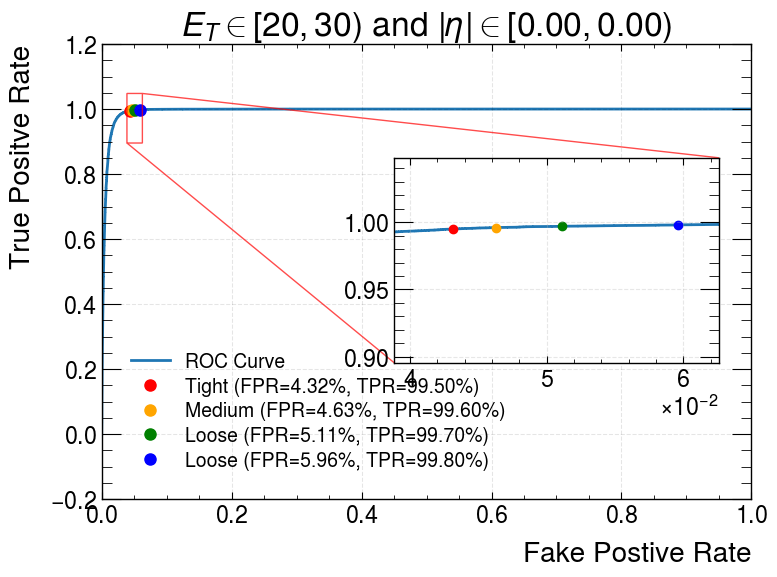

 [Thu, 06 Aug 2026 15:03:54] INFO Substituting symbol \in from Computer Modern


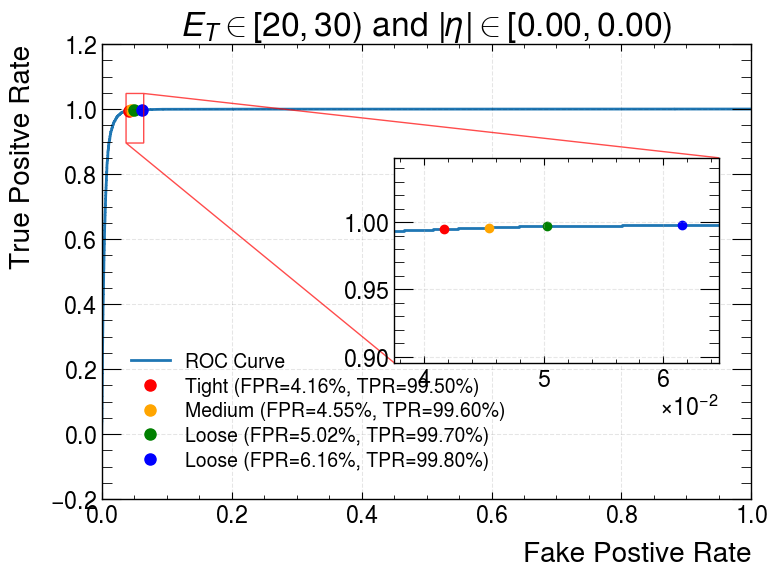

 [Thu, 06 Aug 2026 15:03:54] INFO Substituting symbol \in from Computer Modern


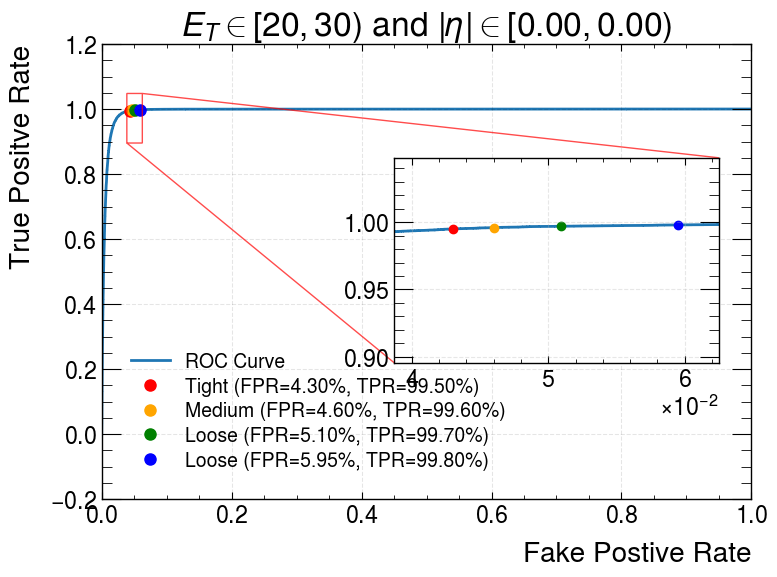

 [Thu, 06 Aug 2026 15:03:55] INFO Substituting symbol \in from Computer Modern


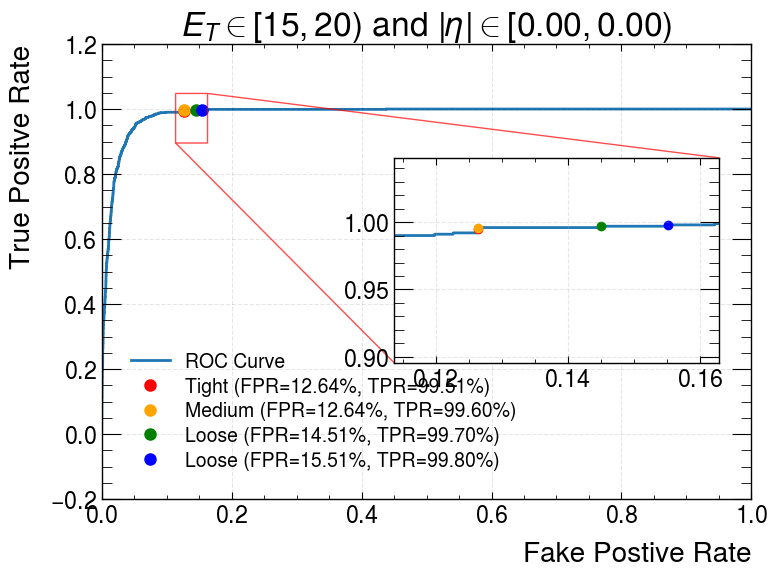

 [Thu, 06 Aug 2026 15:03:55] INFO Substituting symbol \in from Computer Modern


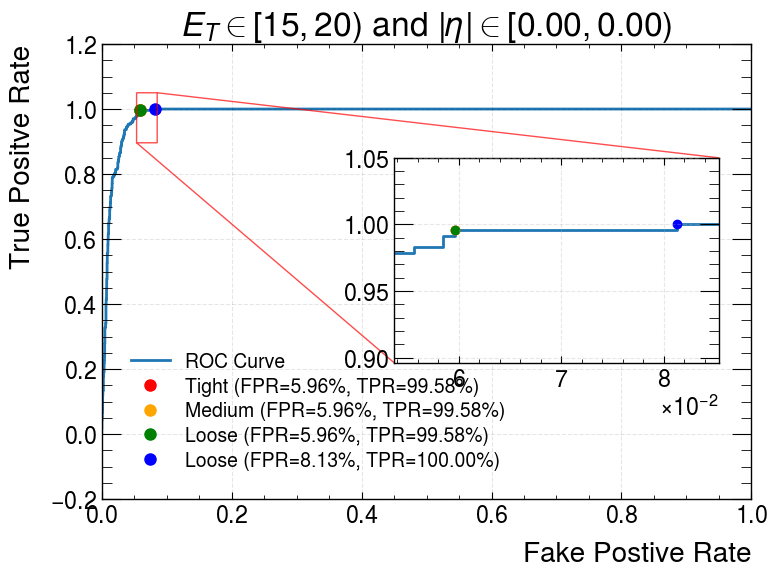

 [Thu, 06 Aug 2026 15:03:55] INFO Substituting symbol \in from Computer Modern


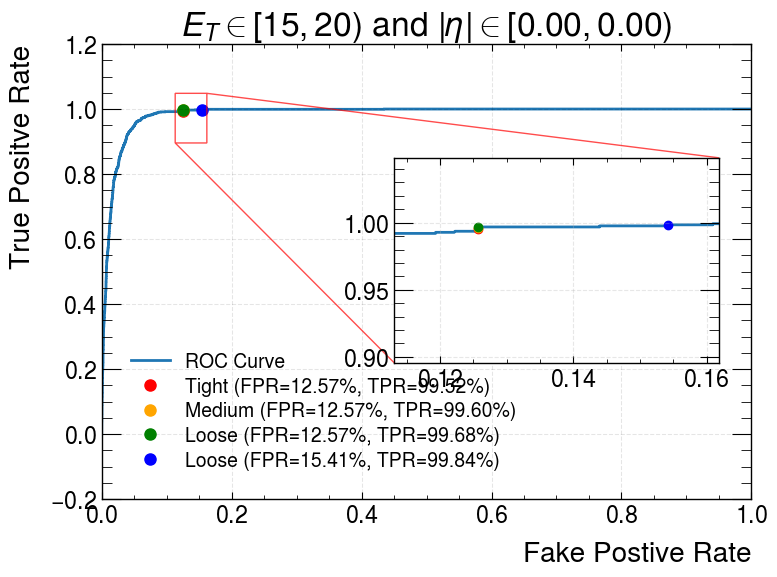

In [ ]:
for i, specialist_to_evaluate in enumerate(specialist_committee.models):
    et_bin = specialist_to_evaluate.training_results['et_bin']
    eta_bin = specialist_to_evaluate.training_results['eta_bin']
    model_id = specialist_to_evaluate.training_results['id']
    model_dir = output_dir / f'member_{model_id}'
    model_dir.mkdir(parents=True, exist_ok=True)
    logger.info(f"{i} - Evaluating model with et bin: {et_bin}, eta bin: {eta_bin}")
    dataset = training_job.get_dataset(
        specialist_to_evaluate.training_results['fold'],
        et_bin=et_bin, eta_bin=eta_bin,
        dataset_dir='/home/lucasbanunes/data/ringer-datasets/datasets/mc21_isabela_qt_2sigma_restriction'
    )
    data_df = dataset.predict_df()
    logger.info('Predicting on the evaluation dataset...')
    prediction_df = data_df.pipe(specialist_to_evaluate.predict, passthrough=True, batch_size=1024)
    cm_dfs = []
    for dataset_type in dataset_types:
        logger.info(f"Computing confusion matrix for {dataset_type} dataset...")
        cm_df = enhanced_confusion_matrix_from_polars(
            data=prediction_df.filter(pl.col(f'is_{dataset_type}')),
            score_col='output',
            label_col='label'
        )
        cm_dfs.append(cm_df)
    cm_dfs = pl.collect_all(cm_dfs)
    for dataset_type, cm_df in zip(dataset_types, cm_dfs):
        dataset_type_evaluation_results = {
            'confusion_matrix': cm_df
        }
        threshold_fit_results = {}
        for reference_name, reference_info in references.items():
            reference_tpr = reference_info['tpr']
            logger.info(f"Finding threshold for reference TPR of {reference_tpr} in {dataset_type} dataset...")
            reference_tpr_df = (
                cm_df
                .with_columns((pl.col('tpr') - reference_tpr).abs().truediv(reference_tpr).mul(100).alias('relative_tpr_err'))
                .sort("relative_tpr_err")
                .head(5)
            )
            threshold_fit_results[reference_name] = reference_tpr_df.row(0, named=True)
            threshold_fit_results[reference_name]['ref'] = reference_info
        fig, _, _ = plot_roc_curve(
            cm_df,
            tpr_col='tpr', fpr_col='fpr',
            threshold_fit_results=threshold_fit_results,
            references=references,
            et_bin=et_bin, eta_bin=eta_bin
        )
        fig.savefig(model_dir / f'{dataset_type}_roc_curve_threshold_fit.png', dpi=300)
        specialist_to_evaluate.training_results[dataset_type] = threshold_fit_results

In [ ]:
all_training_results = []
for model in specialist_committee.models:
    training_results = model.training_results.copy()
    for dataset_type, ref in product(dataset_types, references):
        if 'confusion_matrix' not in training_results[dataset_type]:
            continue
        training_results[dataset_type] = training_results[dataset_type].copy()
        # Removes the dataframes
        training_results[dataset_type].pop('confusion_matrix')
    all_training_results.append(training_results)
all_training_results_df = pl.from_records(all_training_results)
all_training_results_df = unnest_structs(all_training_results_df)
all_training_results_df.write_parquet(evaluation_dir / 'results.parquet')
all_training_results_df

fold,init,et_bin.low,et_bin.high,et_bin.closed,eta_bin.low,eta_bin.high,eta_bin.closed,history.start,history.end,history.train.accuracy,history.train.loss,history.val.accuracy,history.val.loss,history.val.max_sp,history.val.max_sp_fa,history.val.max_sp_pd,history.val.max_sp_threshold,history.val.max_sp_best_epoch,fit.train.accuracy,fit.train.loss,fit.val.accuracy,fit.val.loss,fit.val.max_sp,fit.val.max_sp_fa,fit.val.max_sp_pd,fit.val.max_sp_threshold,fit.val.max_sp_best_epoch,id,train.tight.tp,train.tight.fp,train.tight.positives,train.tight.negatives,train.tight.fn,train.tight.tn,train.tight.total,train.tight.correct,…,test.medium.ref.tpr,test.medium.ref.color,test.medium.ref.label,test.loose.tp,test.loose.fp,test.loose.positives,test.loose.negatives,test.loose.fn,test.loose.tn,test.loose.total,test.loose.correct,test.loose.incorrect,test.loose.tpr,test.loose.fpr,test.loose.accuracy,test.loose.sp,test.loose.relative_tpr_err,test.loose.ref.tpr,test.loose.ref.color,test.loose.ref.label,test.very_loose.tp,test.very_loose.fp,test.very_loose.positives,test.very_loose.negatives,test.very_loose.fn,test.very_loose.tn,test.very_loose.total,test.very_loose.correct,test.very_loose.incorrect,test.very_loose.tpr,test.very_loose.fpr,test.very_loose.accuracy,test.very_loose.sp,test.very_loose.relative_tpr_err,test.very_loose.ref.tpr,test.very_loose.ref.color,test.very_loose.ref.label
i64,i64,f64,str,str,f64,f64,str,str,str,list[f64],list[f64],list[f64],list[f64],list[f64],list[f64],list[f64],list[f64],list[i64],f64,f64,f64,f64,f64,f64,f64,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,…,f64,str,str,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,str,str,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,str,str
3,3,20000.0,"""30000.0""","""left""",2.37,2.5,"""left""","""2026-08-06T10:23:44.116053""","""2026-08-06T10:24:38.454370""","[0.502663, 0.31658, … 0.956979]","[0.715723, 0.709551, … 0.109306]","[0.418415, 0.222283, … 0.955598]","[0.702548, 0.704122, … 0.11684]","[0.184878, 0.217783, … 0.970805]","[0.985726, 0.978985, … 0.045202]","[0.679721, 0.739774, … 0.986945]","[0.476397, 0.488161, … 0.661855]","[0, 1, … 230]",0.956364,0.111337,0.954781,0.119147,0.970868,0.046788,0.988686,0.647548,230,243,4723,720,4747,9897,24,9177,14644,13900,…,0.996,"""orange""","""Medium""",5878,993,5896,12419,18,11426,18315,17304,1011,0.996947,0.079958,0.944799,0.958109,0.005308,0.997,"""green""","""Loose""",5884,1149,5896,12419,12,11270,18315,17154,1161,0.997965,0.09252,0.936609,0.952185,0.003535,0.998,"""blue""","""Loose"""
4,0,50000.0,"""Infinity""","""left""",1.52,2.37,"""left""","""2026-08-06T11:18:14.219426""","""2026-08-06T11:19:18.321098""","[0.25451, 0.473368, … 0.992863]","[0.694395, 0.690313, … 0.03919]","[0.43064, 0.628458, … 0.994509]","[0.694559, 0.690778, … 0.030549]","[0.574373, 0.792479, … 0.991208]","[0.313271, 0.248972, … 0.014206]","[0.472087, 0.835043, … 0.996637]","[0.498962, 0.497215, … 0.48611]","[0, 1, … 157]",0.993222,0.040084,0.994509,0.031276,0.991396,0.013832,0.996637,0.512944,157,595,47554,193,47793,10633,239,10440,58426,57994,…,0.996,"""orange""","""Medium""",59508,257,59687,13308,179,13051,72995,72559,436,0.997001,0.019312,0.994027,0.988828,0.000103,0.997,"""green""","""Loose""",59568,302,59687,13308,119,13006,72995,72574,421,0.998006,0.022693,0.994232,0.987629,0.000628,0.998,"""blue""","""Loose"""
4,1,40000.0,"""50000.0""","""left""",0.0,0.8,"""left""","""2026-08-06T10:47:52.218776""","""2026-08-06T10:49:40.360431""","[0.584135, 0.974071, … 0.995847]","[0.625228, 0.449523, … 0.024737]","[0.933148, 0.990144, … 0.995584]","[0.62694, 0.485258, … 0.019264]","[0.979599, 0.984888, … 0.994067]","[0.029066, 0.017647, … 0.008651]","[0.988303, 0.987427, … 0.996788]","[0.477539, 0.509581, … 0.405177]","[0, 1, … 100]",0.995952,0.024931,0.995305,0.02081,0.994156,0.008651,0.996966,0.356685,100,396,245330,109,246563,11564,1233,11455,258127,256785,…,0.996,"""orange""","""Medium""",307279,156,308204,14454,925,14298,322658,3215

In [10]:
committee_results_df = all_training_results_df
exprs = []
second_level_exprs = []
for dataset_type, ref_type in product(dataset_types, references):
    logger.info(f'Adding expressions for {dataset_type} - {ref_type}')
    tp = pl.col(f'{dataset_type}.{ref_type}.tp').sum()
    tn = pl.col(f'{dataset_type}.{ref_type}.tn').sum()
    fp = pl.col(f'{dataset_type}.{ref_type}.fp').sum()
    fn = pl.col(f'{dataset_type}.{ref_type}.fn').sum()
    correct = pl.col(f'{dataset_type}.{ref_type}.correct').sum()
    incorrect = pl.col(f'{dataset_type}.{ref_type}.incorrect').sum()
    positives = pl.col(f'{dataset_type}.{ref_type}.positives').sum()
    negatives = pl.col(f'{dataset_type}.{ref_type}.negatives').sum()
    total = pl.col(f'{dataset_type}.{ref_type}.total').sum()
    exprs.append(tp)
    exprs.append(tn)
    exprs.append(fp)
    exprs.append(fn)
    exprs.append(correct)
    exprs.append(incorrect)
    exprs.append(positives)
    exprs.append(negatives)
    exprs.append(total)

    tpr = tp.truediv(positives)
    fpr = fp.truediv(negatives)
    second_level_exprs.append(tpr.alias(f'{dataset_type}.{ref_type}.tpr'))
    second_level_exprs.append(fpr.alias(f'{dataset_type}.{ref_type}.fpr'))
    second_level_exprs.append(correct.truediv(total).alias(f'{dataset_type}.{ref_type}.accuracy'))
    second_level_exprs.append(polars_sp_index(tpr, fpr).alias(f'{dataset_type}.{ref_type}.sp'))
committee_results_df = (
    all_training_results_df
    .select(*exprs)
    .with_columns(*second_level_exprs)
)
committee_results_path = evaluation_dir / 'committee_results.json'
committee_results = committee_results_df.row(0, named=True)
with committee_results_path.open('w') as f:
    json.dump(committee_results, f, indent=4)
committee_results

 [Thu, 06 Aug 2026 15:03:56] INFO Adding expressions for train - tight
 [Thu, 06 Aug 2026 15:03:56] INFO Adding expressions for train - medium
 [Thu, 06 Aug 2026 15:03:56] INFO Adding expressions for train - loose
 [Thu, 06 Aug 2026 15:03:56] INFO Adding expressions for train - very_loose
 [Thu, 06 Aug 2026 15:03:56] INFO Adding expressions for val - tight
 [Thu, 06 Aug 2026 15:03:56] INFO Adding expressions for val - medium
 [Thu, 06 Aug 2026 15:03:56] INFO Adding expressions for val - loose
 [Thu, 06 Aug 2026 15:03:56] INFO Adding expressions for val - very_loose
 [Thu, 06 Aug 2026 15:03:56] INFO Adding expressions for test - tight
 [Thu, 06 Aug 2026 15:03:56] INFO Adding expressions for test - medium
 [Thu, 06 Aug 2026 15:03:56] INFO Adding expressions for test - loose
 [Thu, 06 Aug 2026 15:03:56] INFO Adding expressions for test - very_loose


{'train.tight.tp': 1526894,
 'train.tight.tn': 949174,
 'train.tight.fp': 59993,
 'train.tight.fn': 7675,
 'train.tight.correct': 2476068,
 'train.tight.incorrect': 67668,
 'train.tight.positives': 1534569,
 'train.tight.negatives': 1009167,
 'train.tight.total': 2543736,
 'train.medium.tp': 1528430,
 'train.medium.tn': 942179,
 'train.medium.fp': 66988,
 'train.medium.fn': 6139,
 'train.medium.correct': 2470609,
 'train.medium.incorrect': 73127,
 'train.medium.positives': 1534569,
 'train.medium.negatives': 1009167,
 'train.medium.total': 2543736,
 'train.loose.tp': 1529965,
 'train.loose.tn': 933027,
 'train.loose.fp': 76140,
 'train.loose.fn': 4604,
 'train.loose.correct': 2462992,
 'train.loose.incorrect': 80744,
 'train.loose.positives': 1534569,
 'train.loose.negatives': 1009167,
 'train.loose.total': 2543736,
 'train.very_loose.tp': 1531500,
 'train.very_loose.tn': 911608,
 'train.very_loose.fp': 97559,
 'train.very_loose.fn': 3069,
 'train.very_loose.correct': 2443108,
 'train.